# 1 Importing Packages

How the *MESSAGE_CA* class works: the class will contain all the functions necessary to run the MESSAGEix Canada model. All that you need to run a model is to:

1. Create your scenario folder under `model/scenarios` with its own `config.toml` file

2. Declare the class reading that scenario, for example: `platform, msg, msg_folder = MESSAGE_CA(scenario_name='baseline')`

In [1]:
from model.message_phases import model_MSG
from model.message_phases import Plotter_MSG

import os
import sys

# Autoreload modules when changiges are applied to them
%load_ext autoreload 
%autoreload all

In [34]:
 %reload_ext autoreload

In [5]:
# Sys and OS Operations
os.chdir("../../")

# Scenario Creation and Set-up

Setting up the MESSAGEix scenario using the scenario configuration file and an input file for technology options in technology.yaml

In [6]:
# Set-up

msg = model_MSG(scenario_name='baseline')
platform, msg_scenario, msg_folder = msg.setup_scenario()

2024-09-25 11:35:37,155  INFO at.ac.iiasa.ixmp.Platform:165 - Welcome to the IX modeling platform!
2024-09-25 11:35:37,165  INFO at.ac.iiasa.ixmp.Platform:166 -  connected to database 'jdbc:hsqldb:file:/Users/muhammadawais/.local/share/ixmp/localdb/default' (user: ixmp)...
Config file read successfully!
####################################################################################################
Config file 'model/scenarios/baseline/config.toml' passed format verification!
####################################################################################################

		Model creation time: 4 Min and 40 Sec 		


In [7]:
df_elec_exp = msg_scenario.par('historical_activity')

In [11]:
import pandas as pd

In [12]:
df = pd.read_csv(msg_folder/'full_elec_exp.csv')

In [15]:
msg_scenario.check_out()

In [16]:
msg_scenario.add_par('bound_activity_up',df)

In [17]:
msg_scenario.commit('added historical activity data')

In [18]:
caseName = caseName = (
			msg_scenario.model
			+ "__"
			+ msg_scenario.scenario
			+ "__v"
			+ str(msg_scenario.version)
		)

In [19]:
msg_scenario.solve(
					solve_options={"barcrossalg": "2", "lpmethod": "1"}, case=caseName
				)

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 09/25/24 13:48:30 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__baseline__v4.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__baseline__v4.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__baseline__v4.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
     

2024-09-25 13:49:12,642 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-09-25 13:49:12,649 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [9]:
msg_scenario.par('bound_activity_up').head()

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,GDP,2010,P,year,1.428747e+03,GWa/a
1,Alberta,GDP,2020,P,year,2.305553e+11,GWa/a
2,Alberta,GDP,2030,P,year,2.809277e+11,GWa/a
3,Alberta,GDP,2040,P,year,3.392062e+11,GWa/a
4,Alberta,GDP,2050,P,year,4.000417e+11,GWa/a


In [8]:
df_elec_exp[df_elec_exp['technology'] == 'elec_exp'].to_csv(msg_folder / 'elec_exp.csv', index=False)

In [1]:
msg_scenario.par('bound_activity_lo')

NameError: name 'msg_scenario' is not defined

In [21]:
msg_plt = Plotter_MSG(msg_scenario)
nodes = msg_scenario.set('node')[2:]


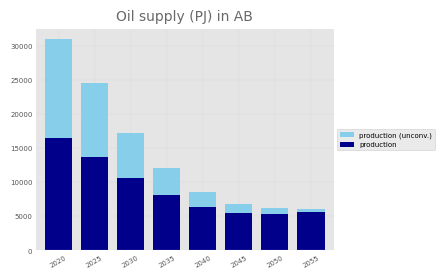

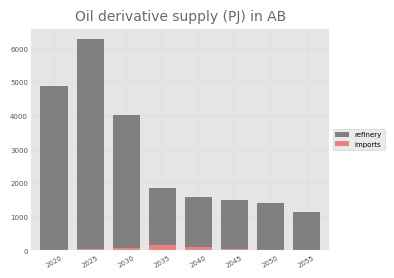

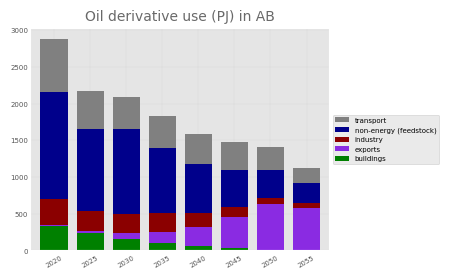

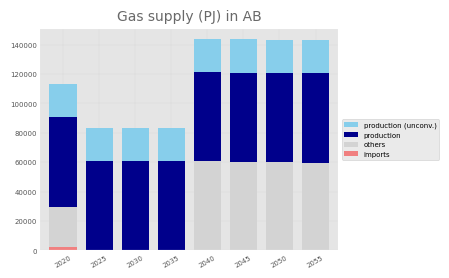

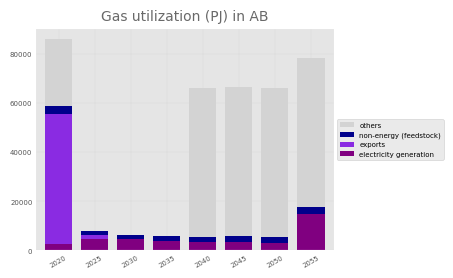

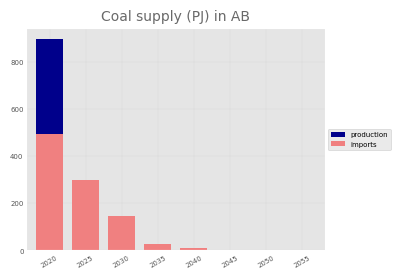

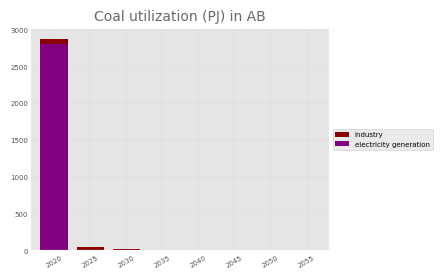

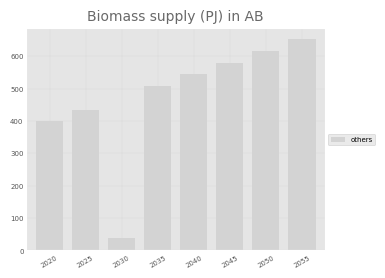

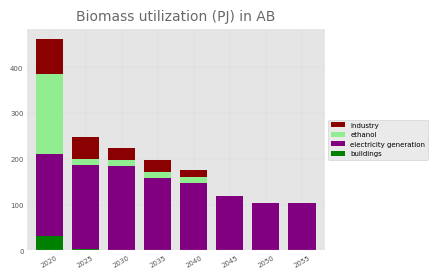

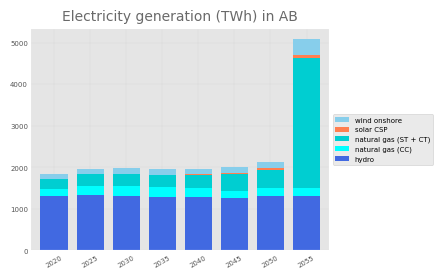

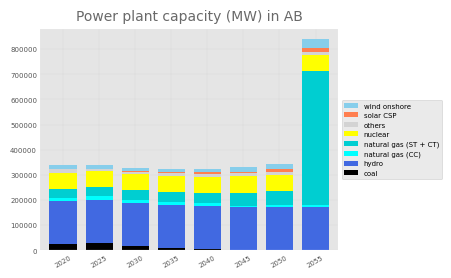

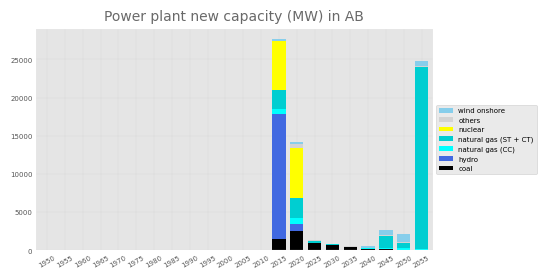

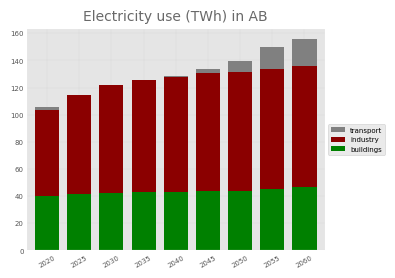

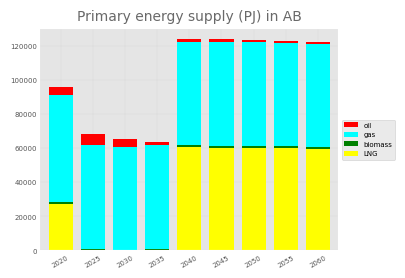

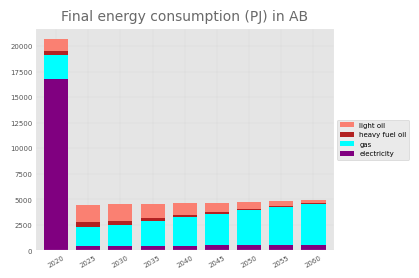

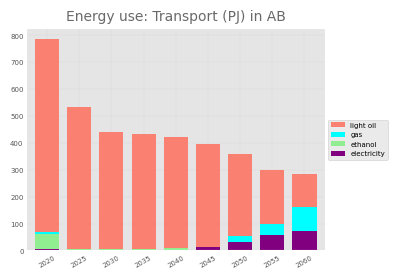

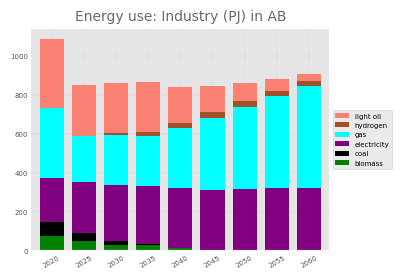

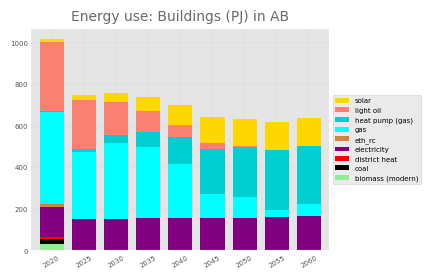

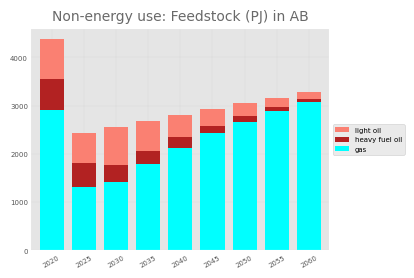

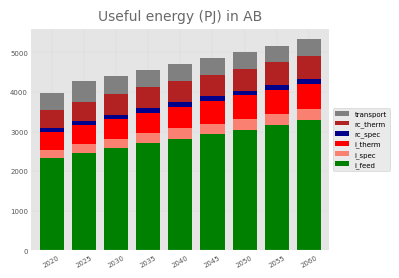

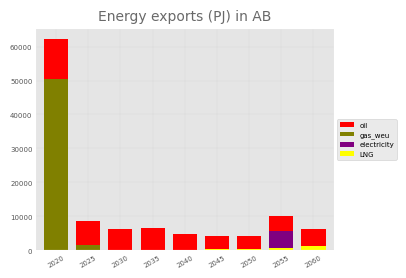

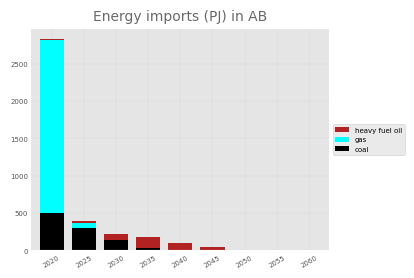

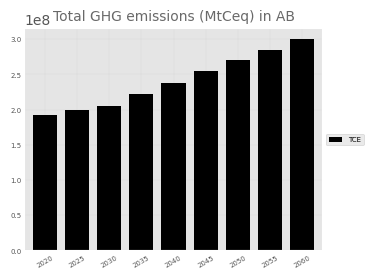

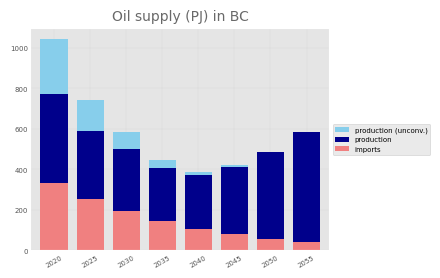

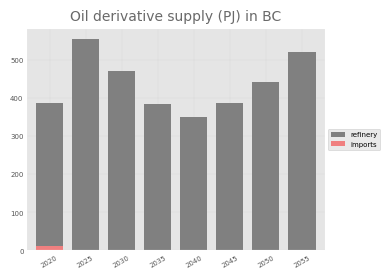

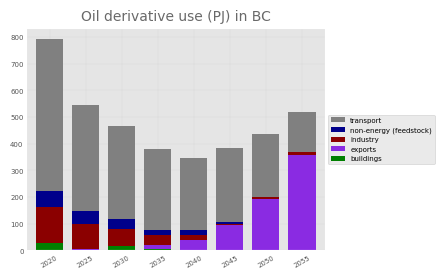

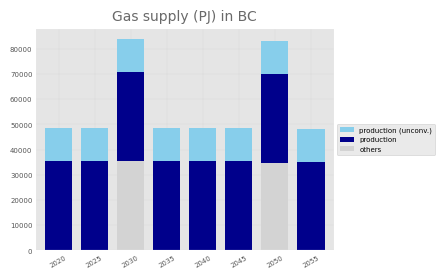

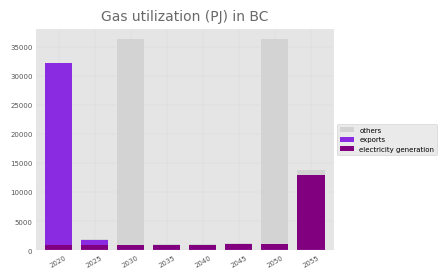

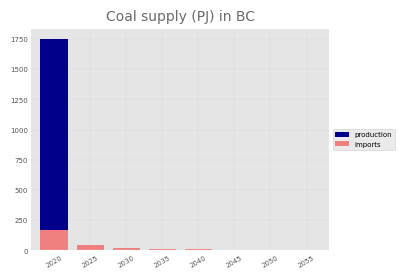

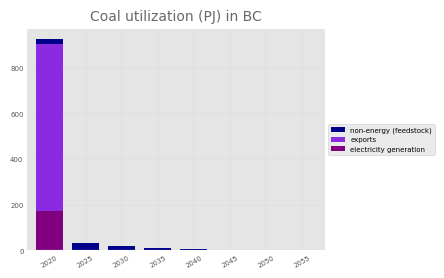

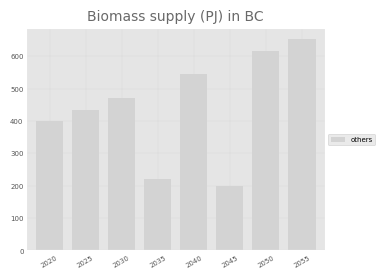

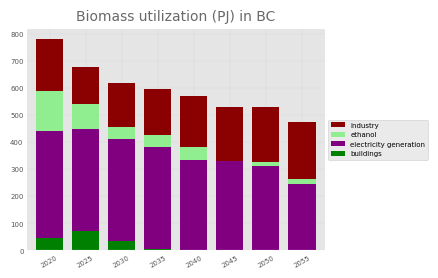

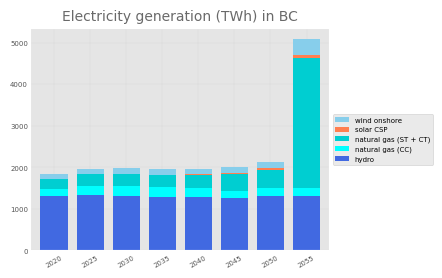

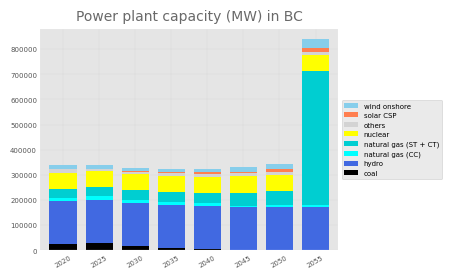

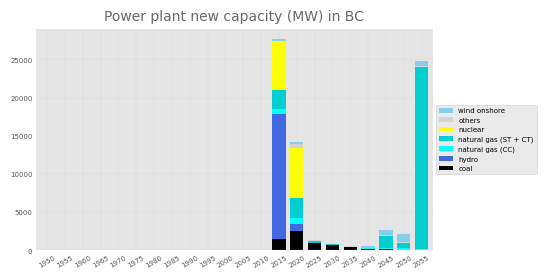

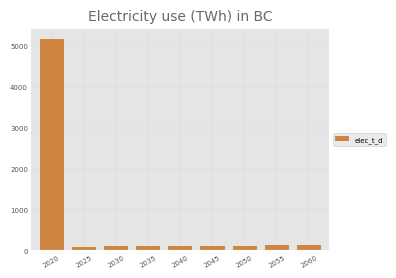

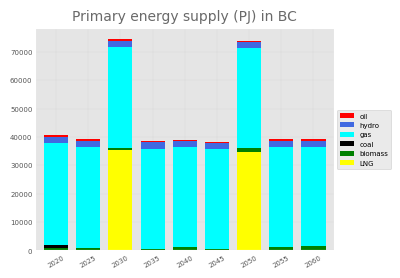

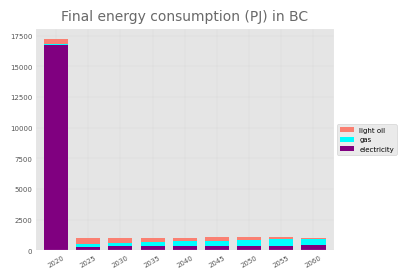

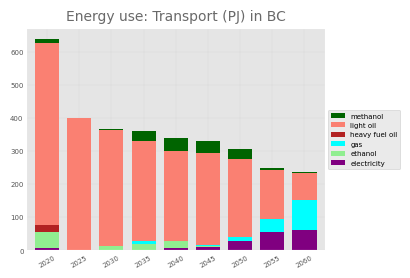

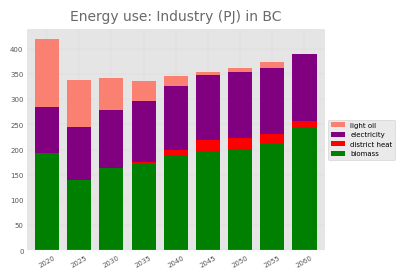

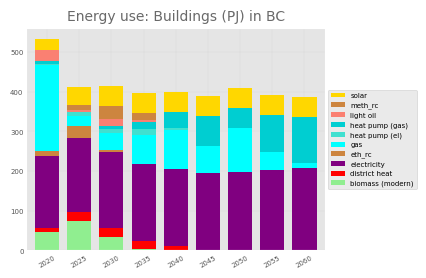

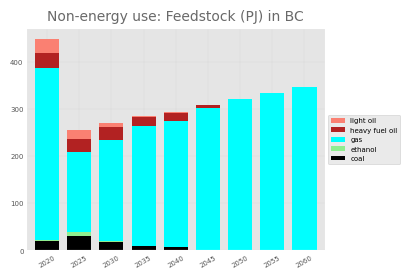

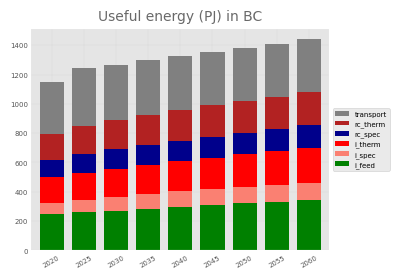

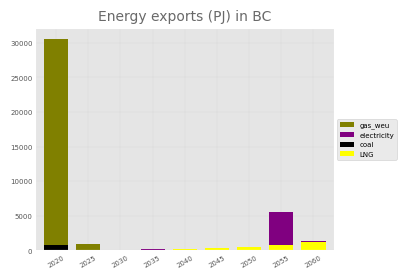

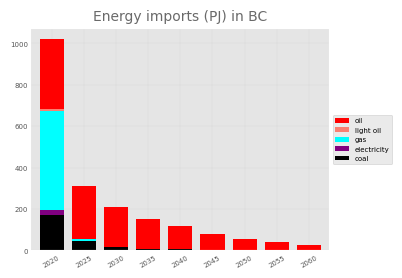

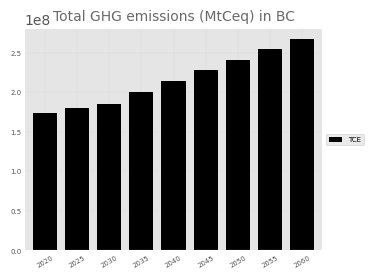

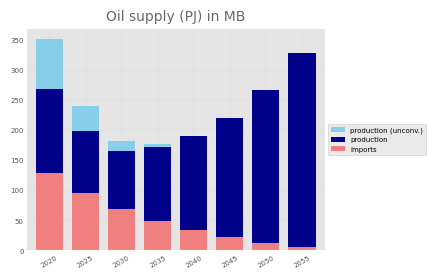

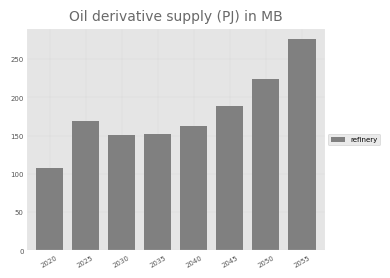

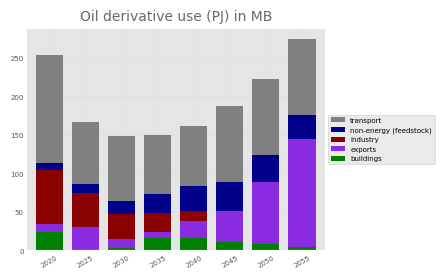

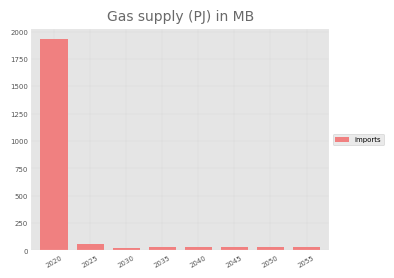

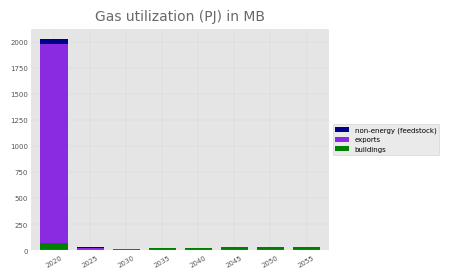

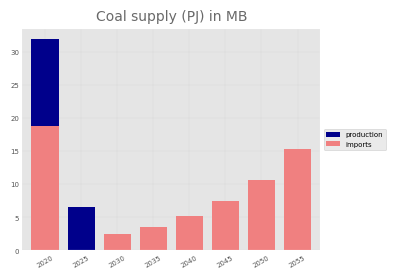

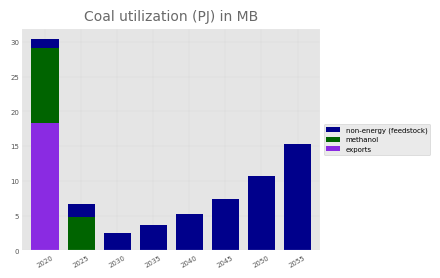

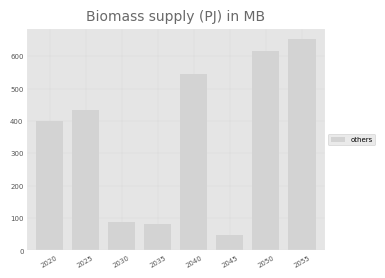

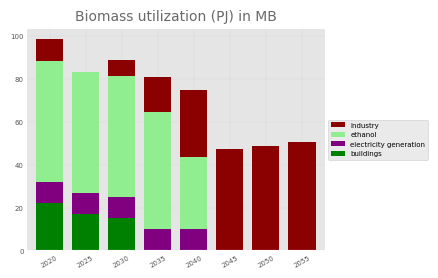

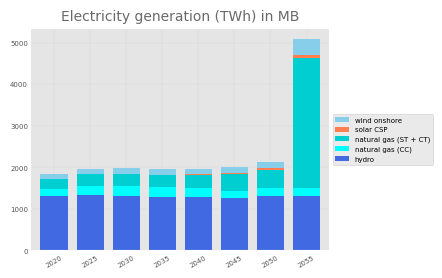

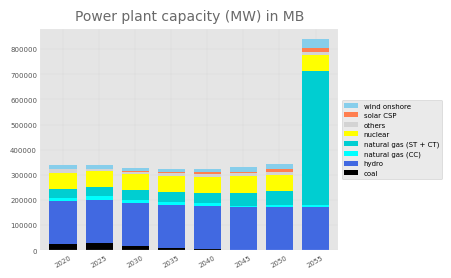

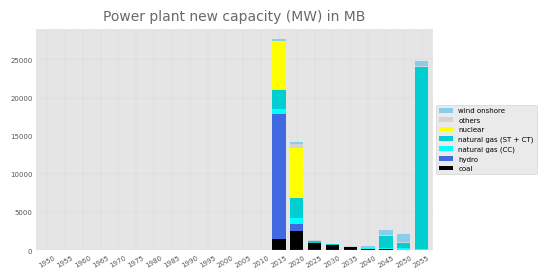

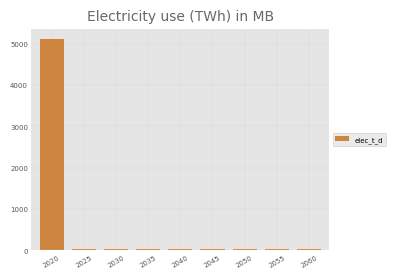

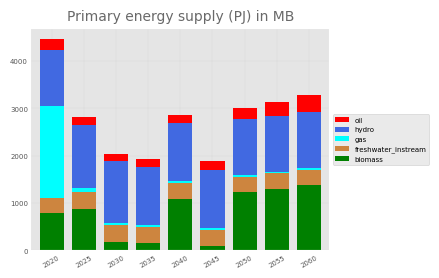

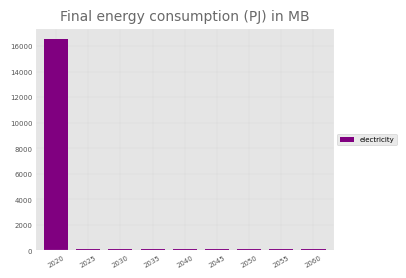

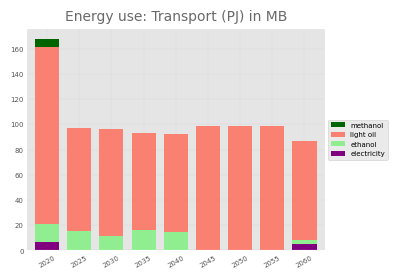

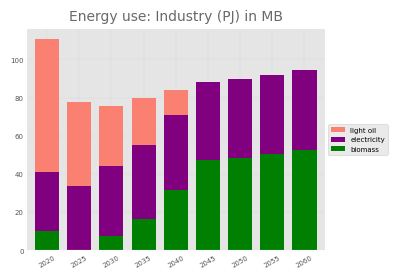

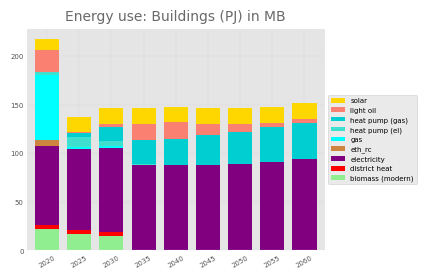

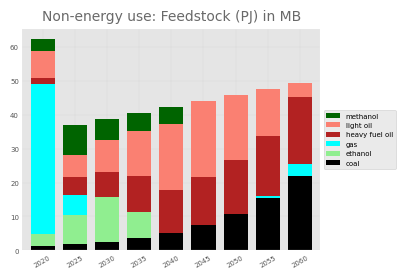

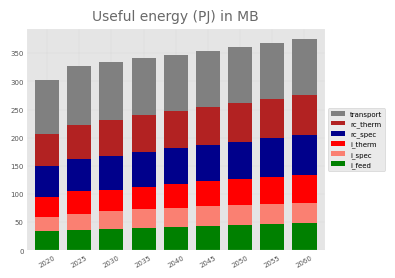

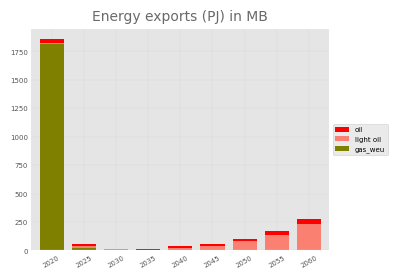

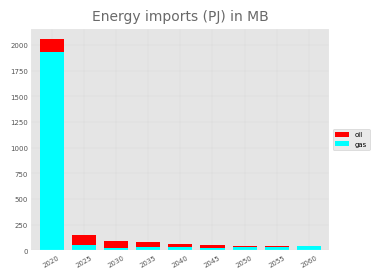

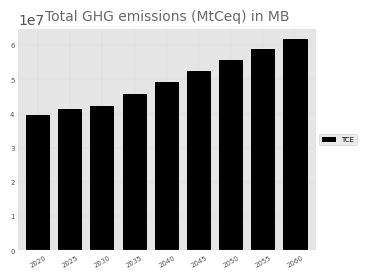

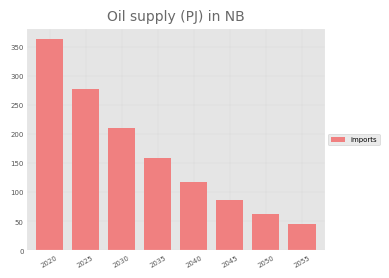

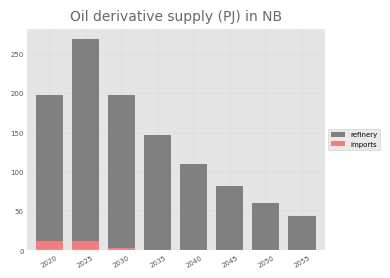

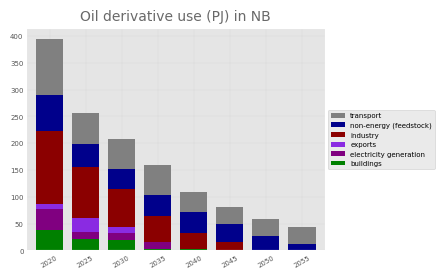

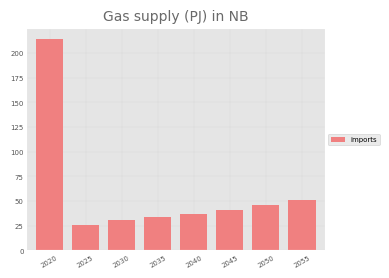

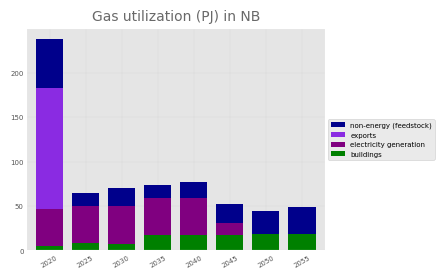

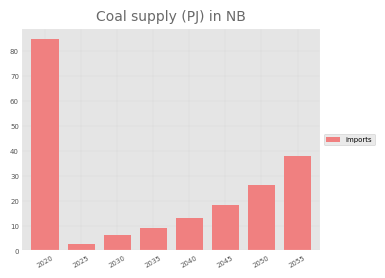

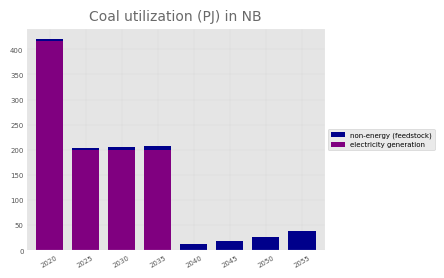

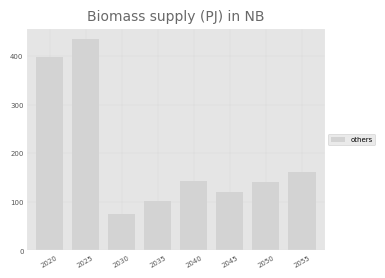

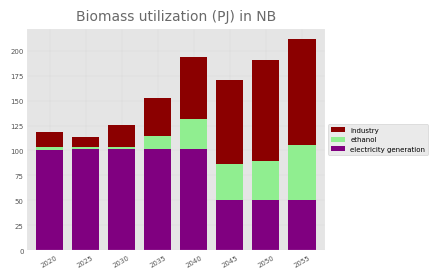

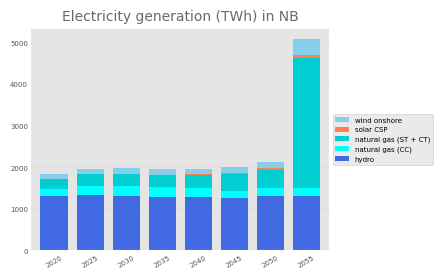

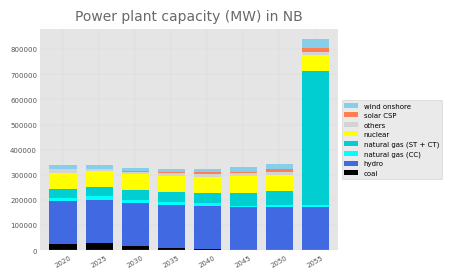

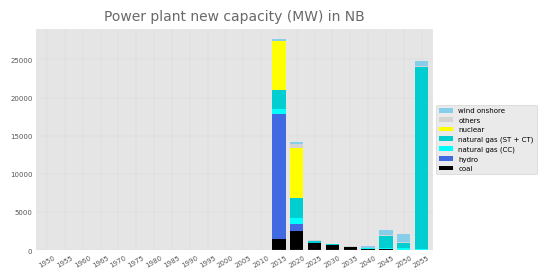

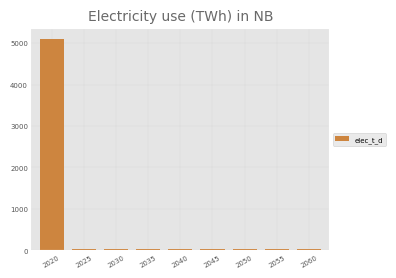

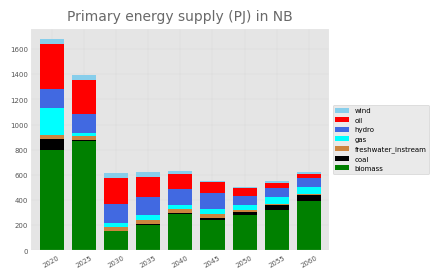

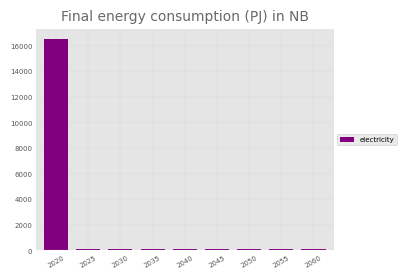

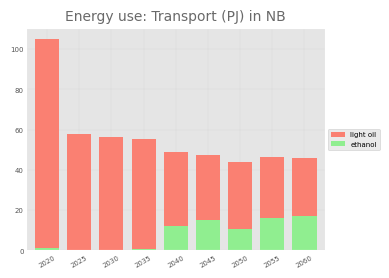

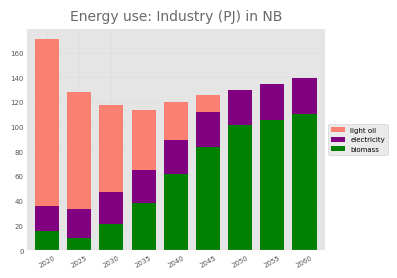

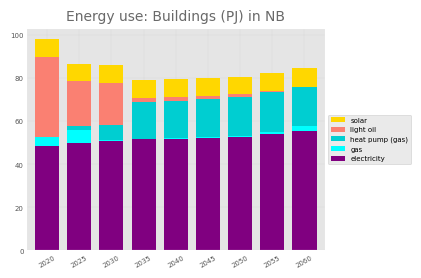

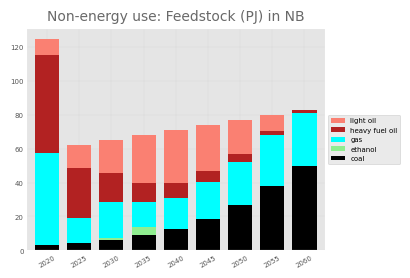

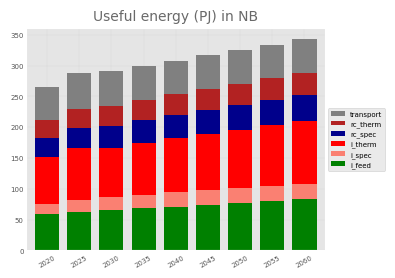

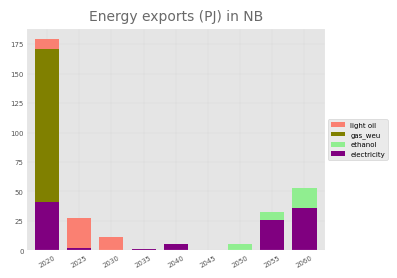

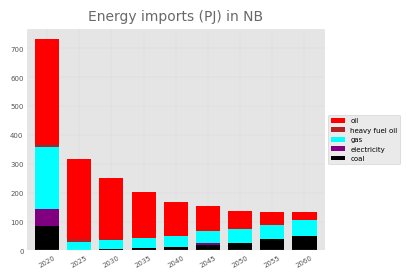

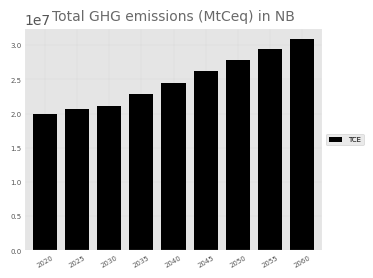

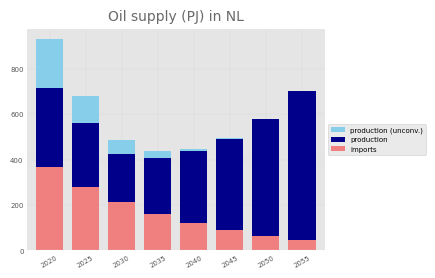

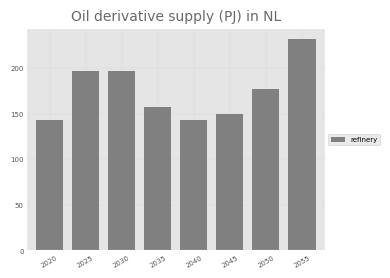

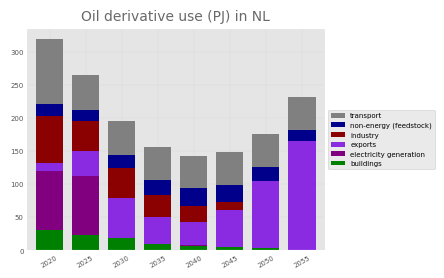

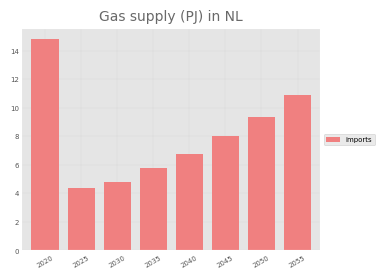

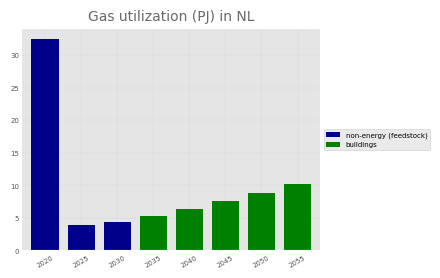

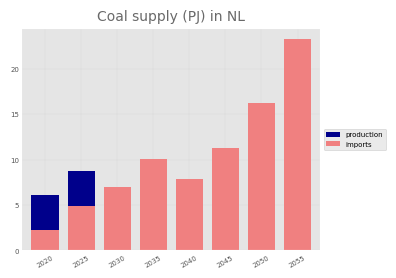

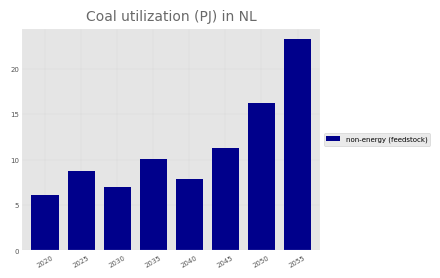

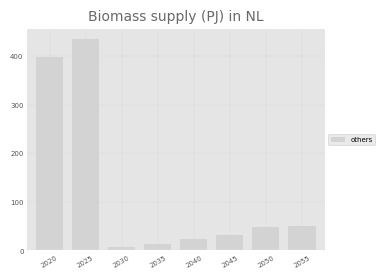

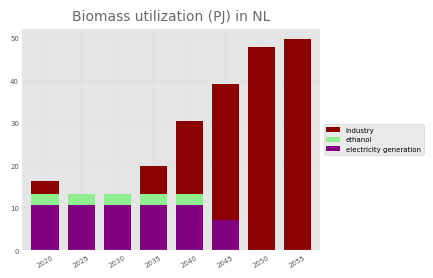

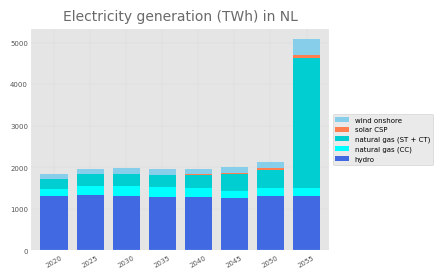

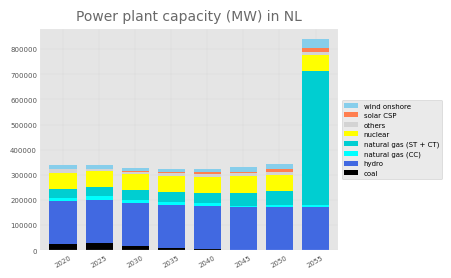

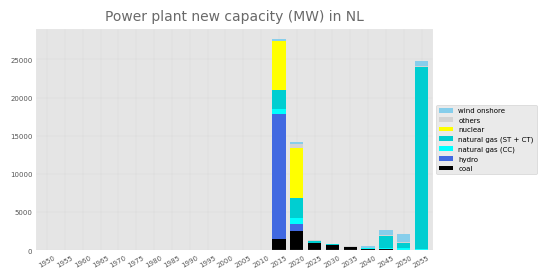

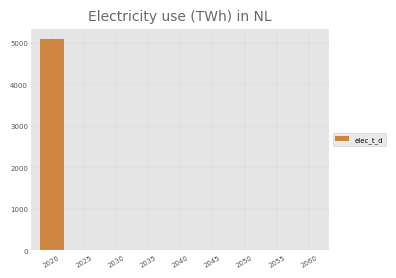

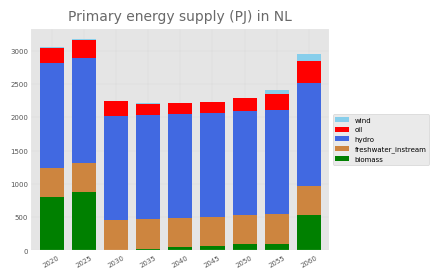

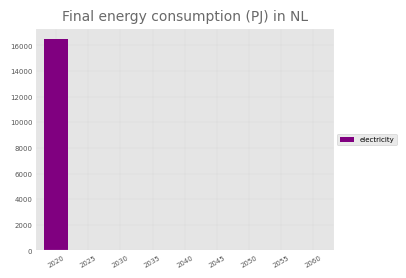

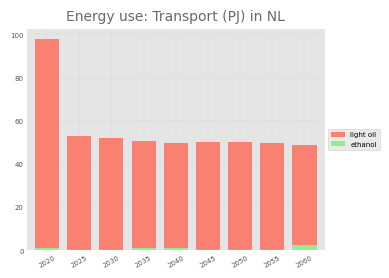

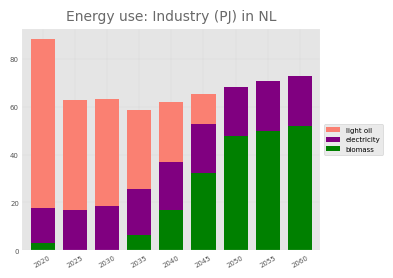

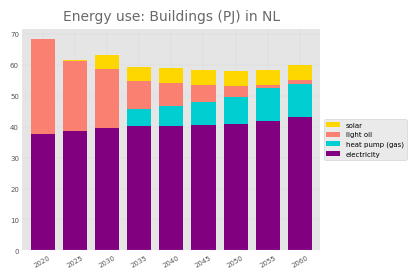

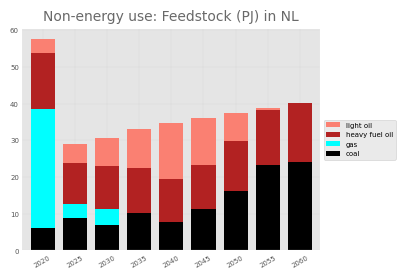

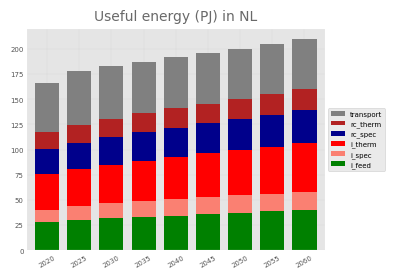

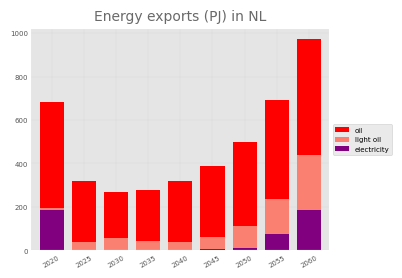

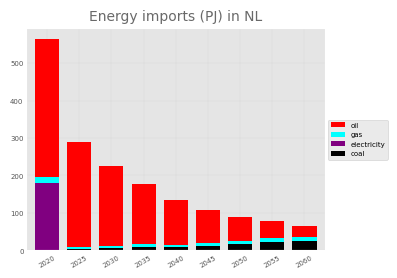

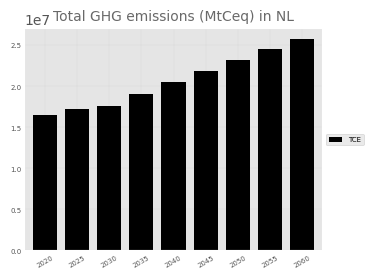

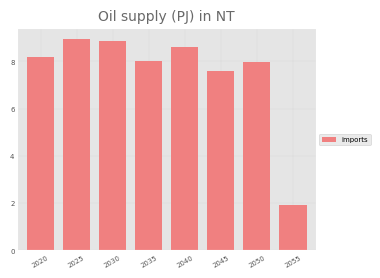

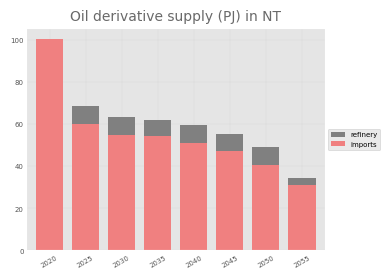

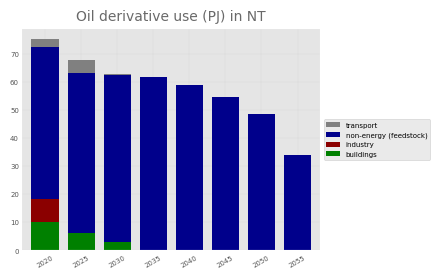

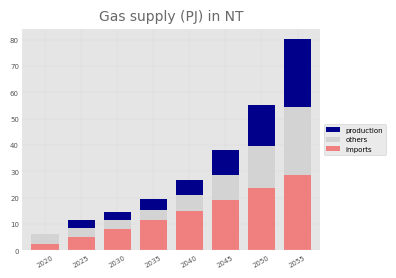

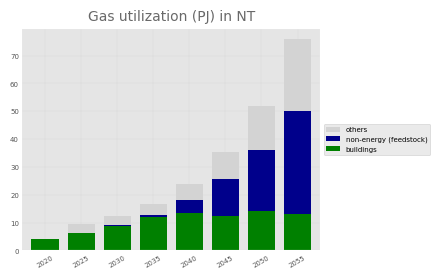

> WARNING: There is no solution data in the selected years and limits to be plotted for Coal supply (PJ)!


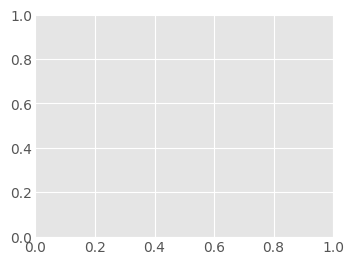

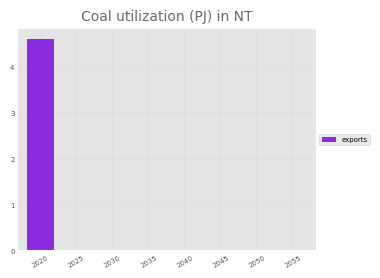

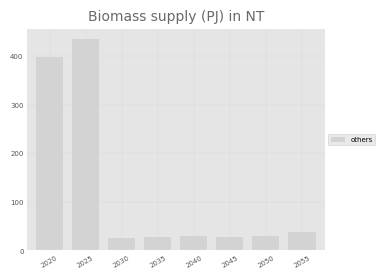

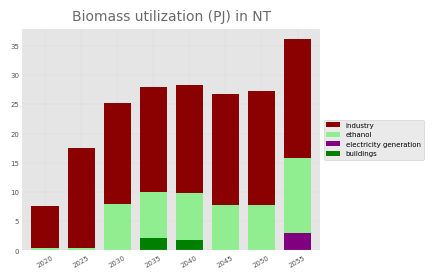

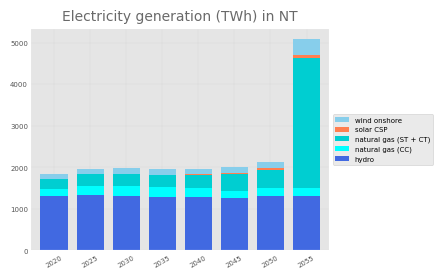

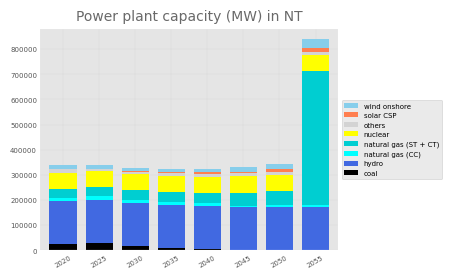

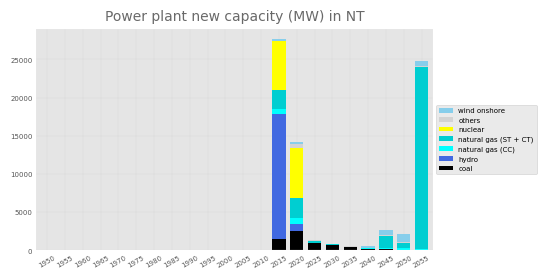

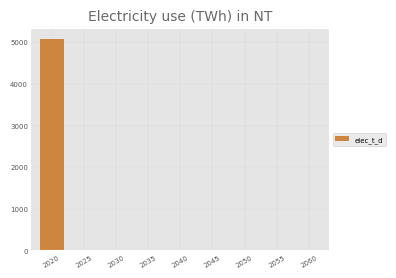

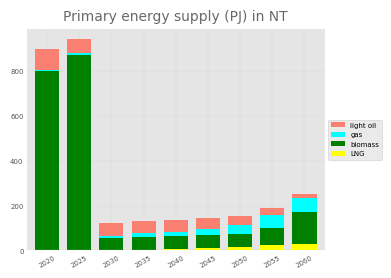

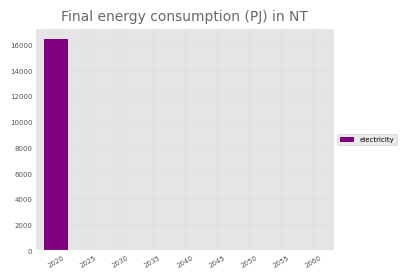

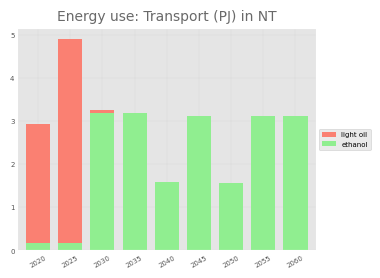

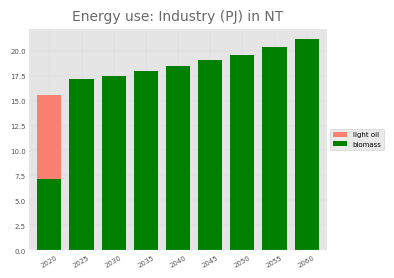

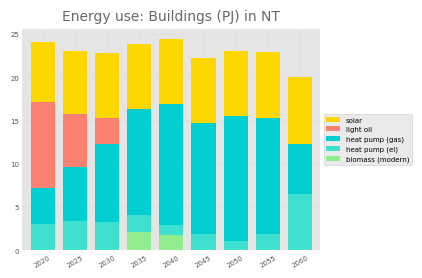

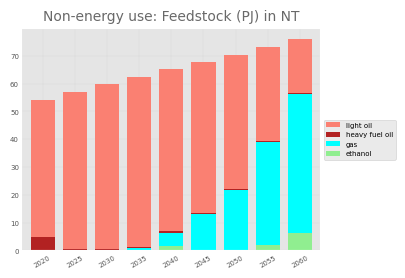

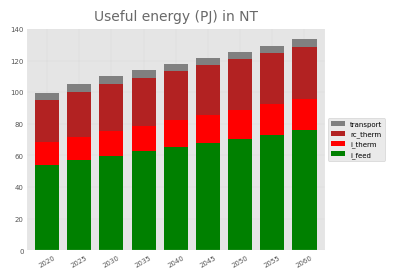

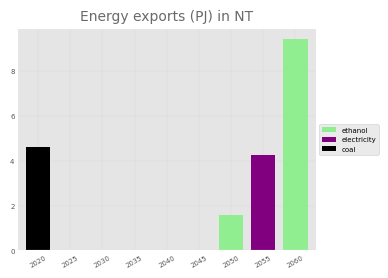

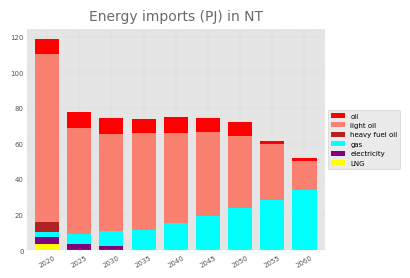

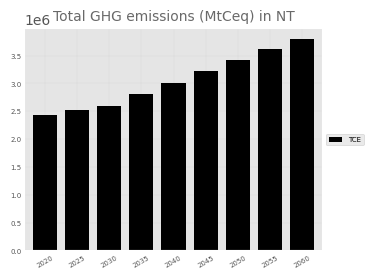

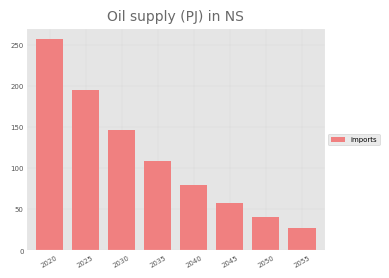

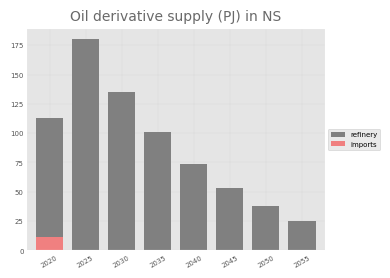

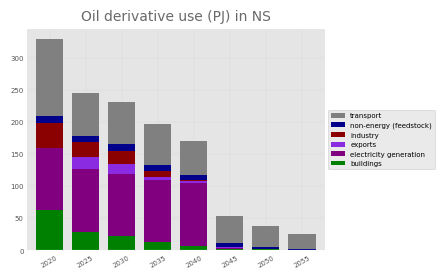

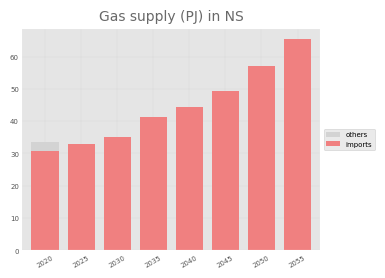

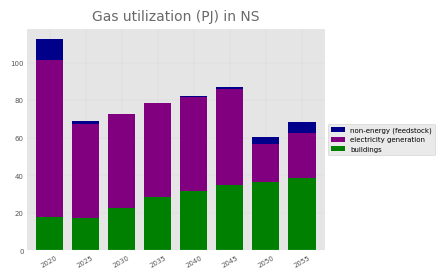

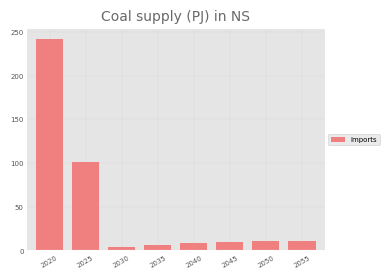

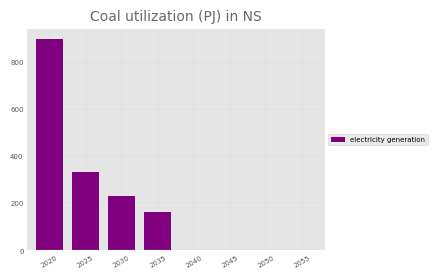

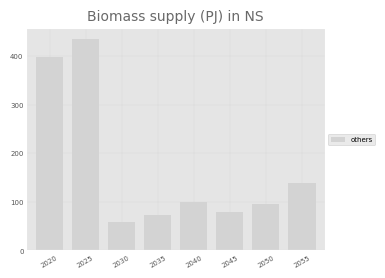

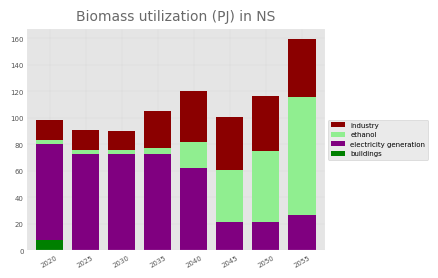

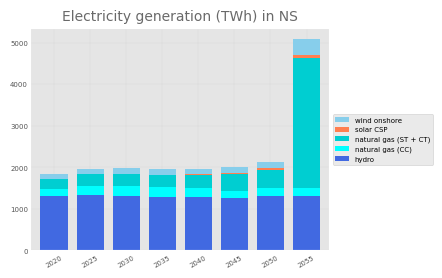

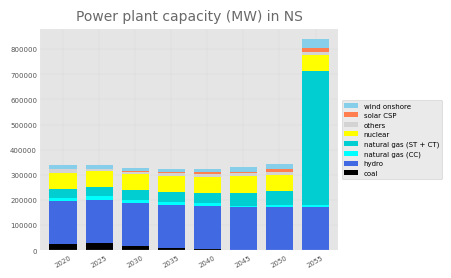

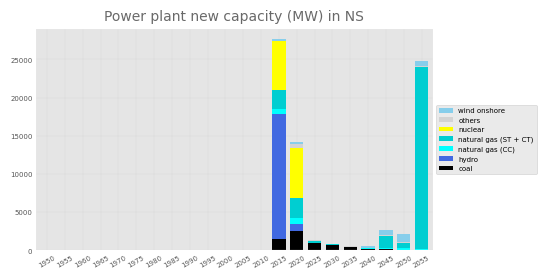

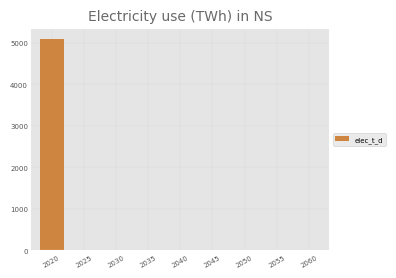

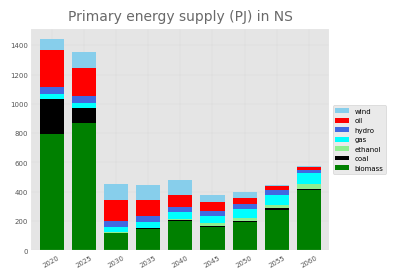

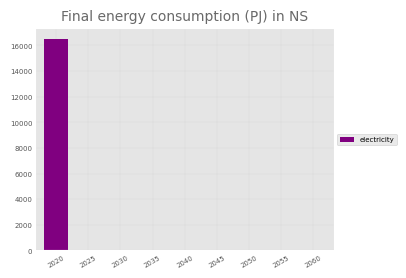

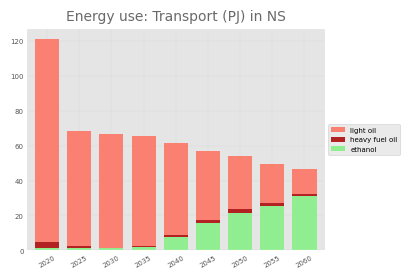

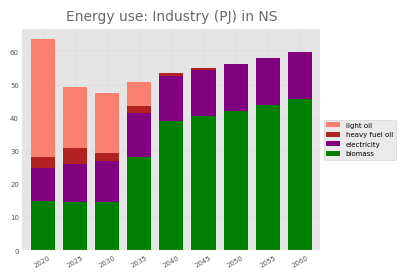

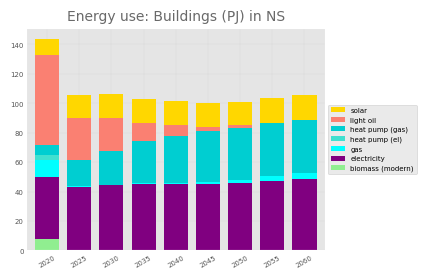

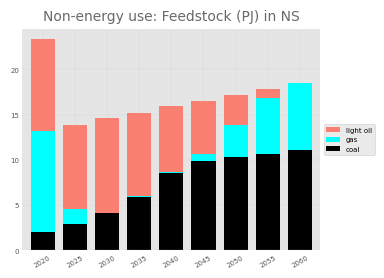

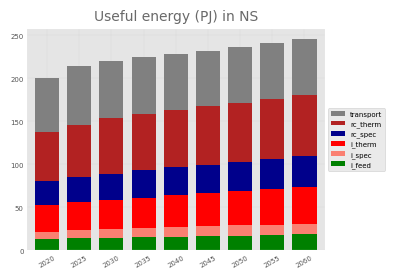

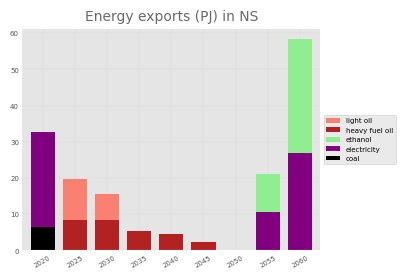

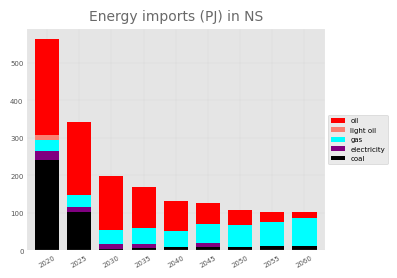

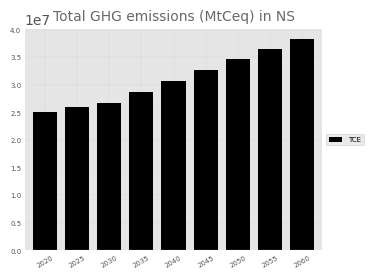

> WARNING: There is no solution data in the selected years and limits to be plotted for Oil supply (PJ)!


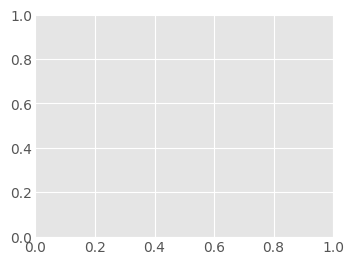

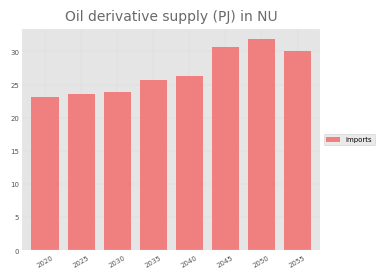

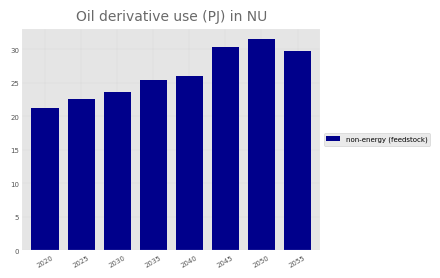

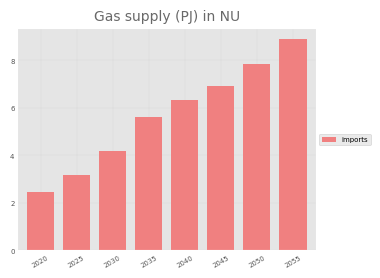

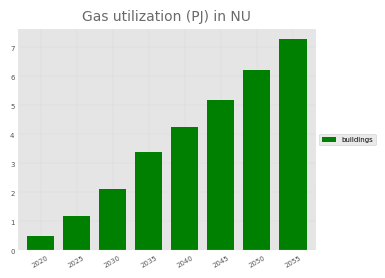

> WARNING: There is no solution data in the selected years and limits to be plotted for Coal supply (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Coal utilization (PJ)!


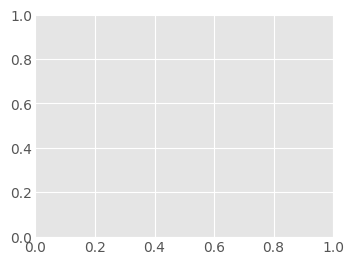

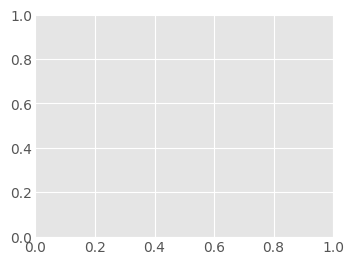

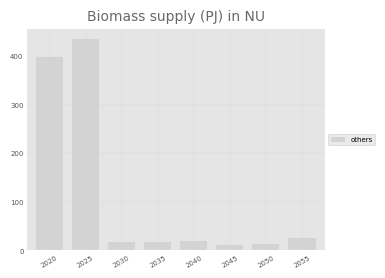

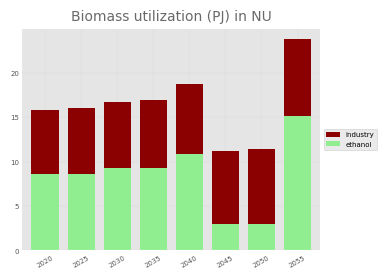

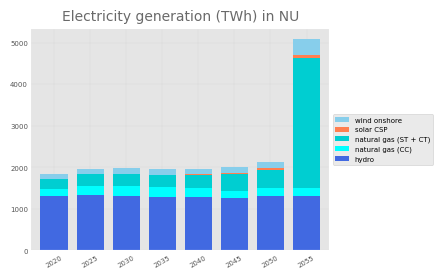

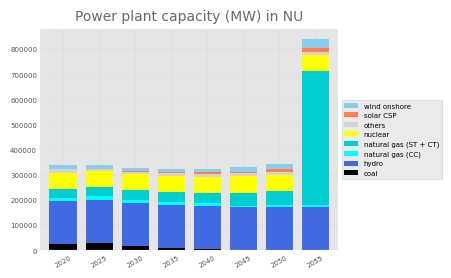

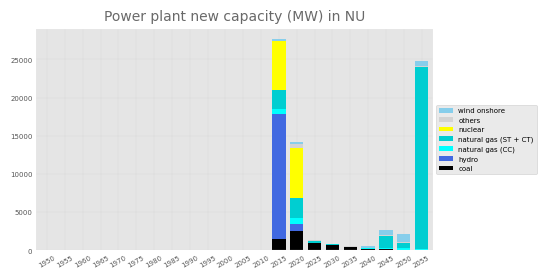

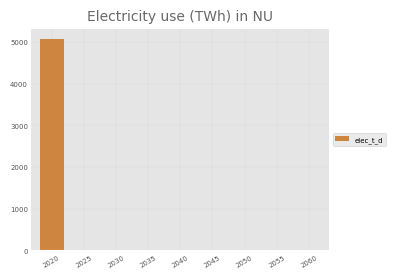

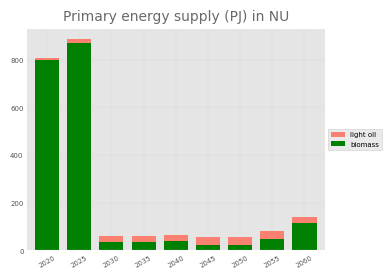

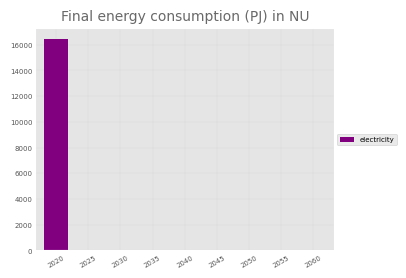

> WARNING: There is no solution data in the selected years and limits to be plotted for Energy use: Transport (PJ)!


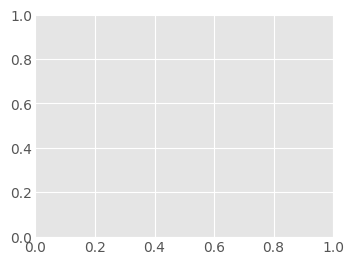

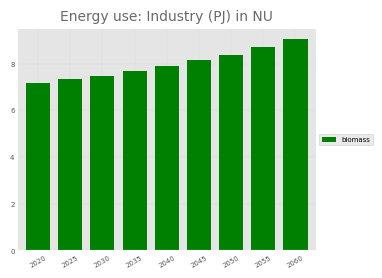

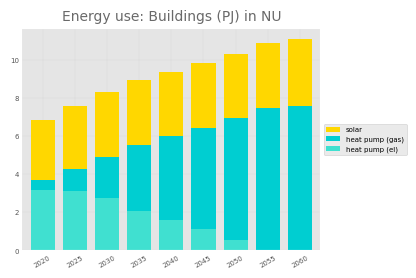

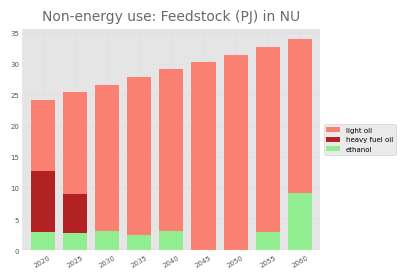

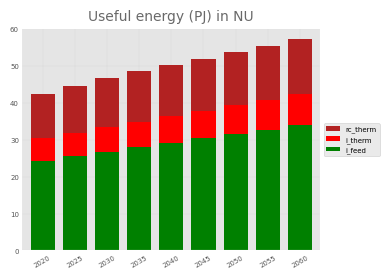

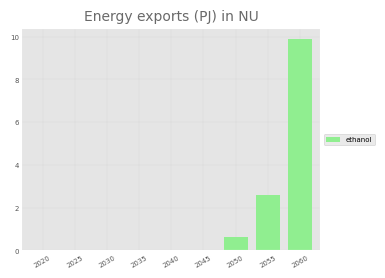

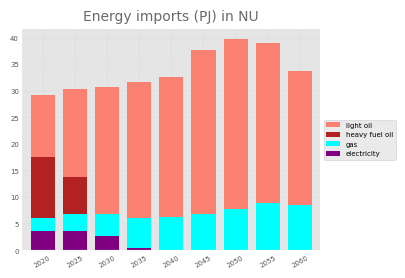

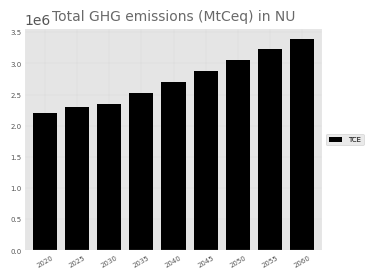

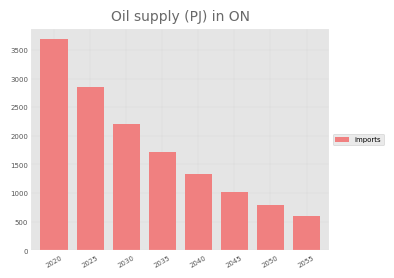

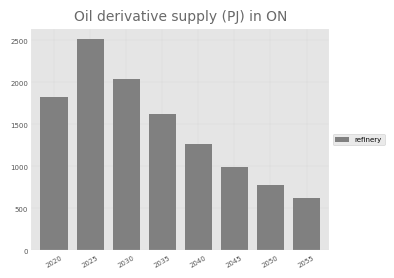

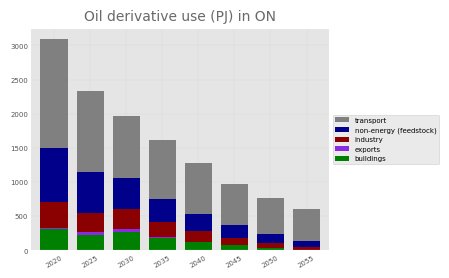

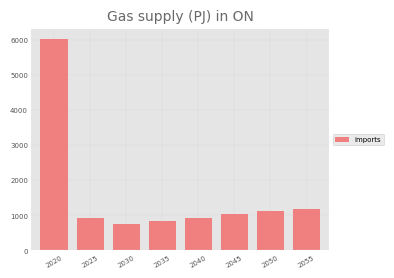

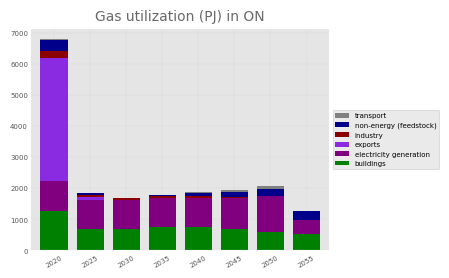

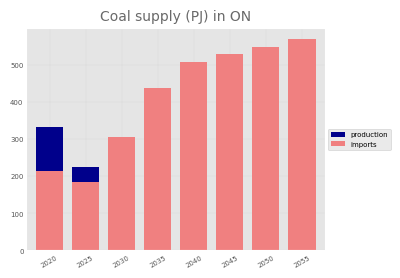

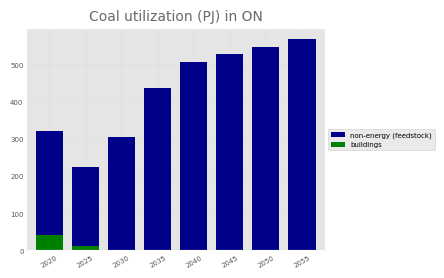

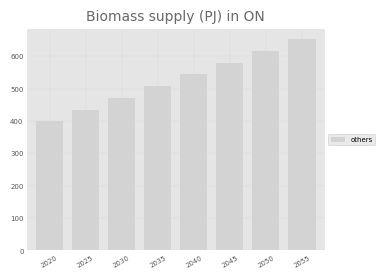

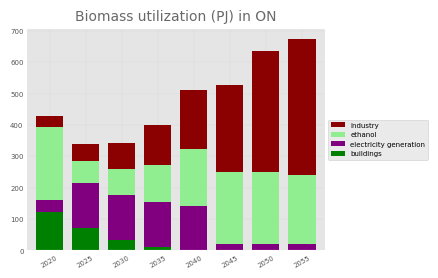

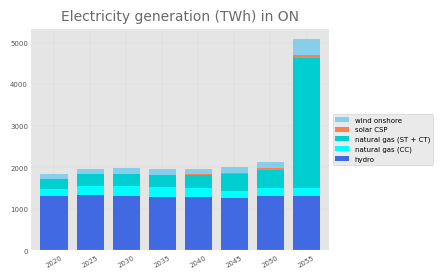

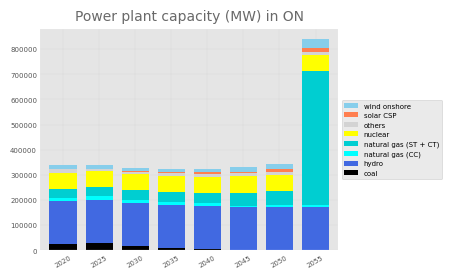

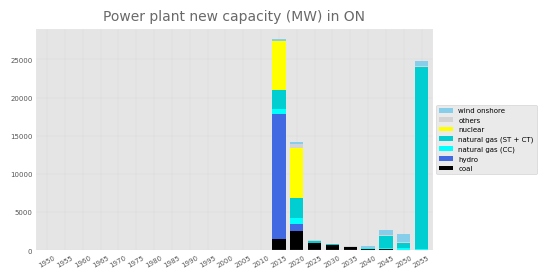

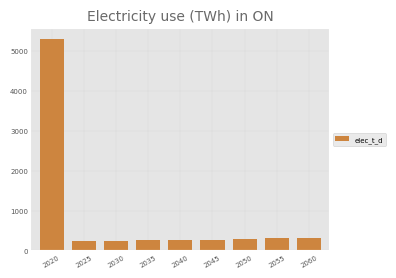

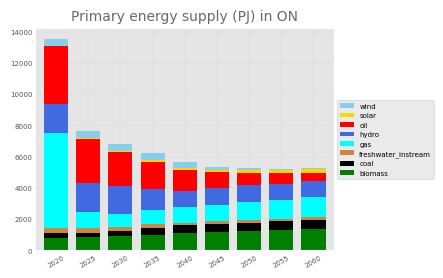

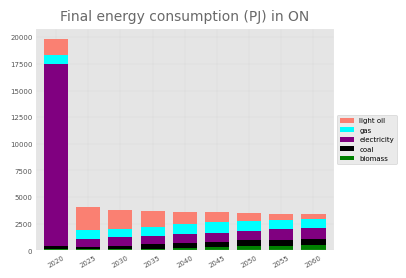

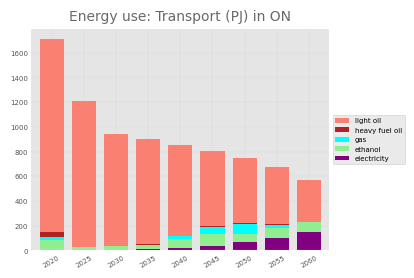

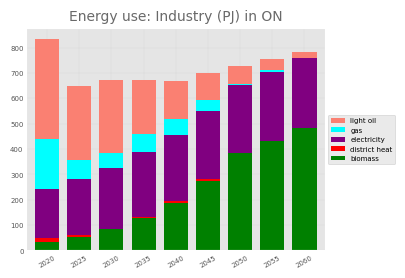

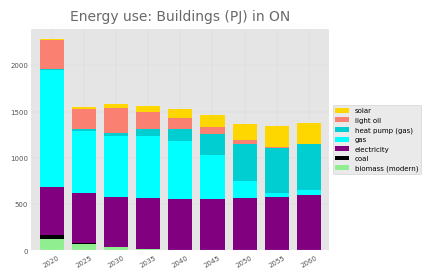

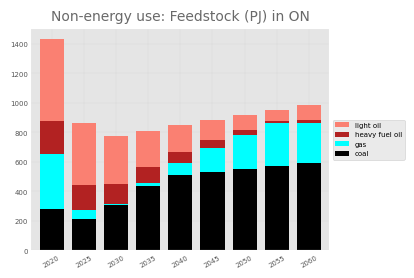

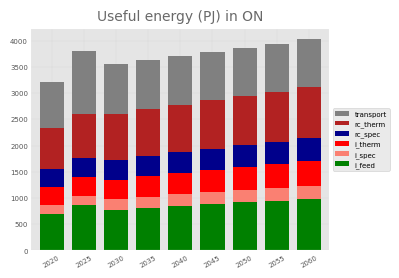

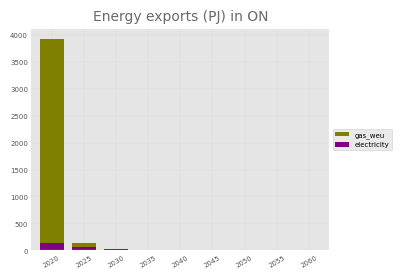

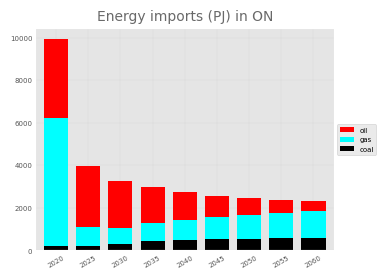

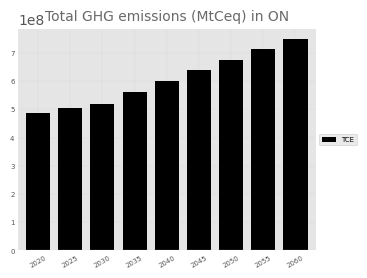

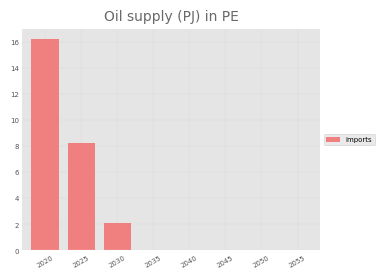

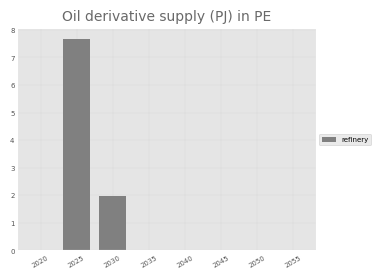

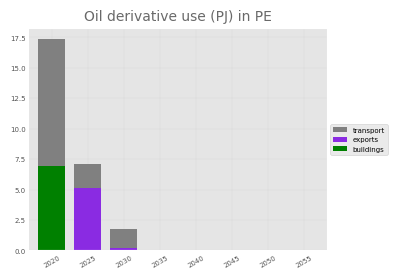

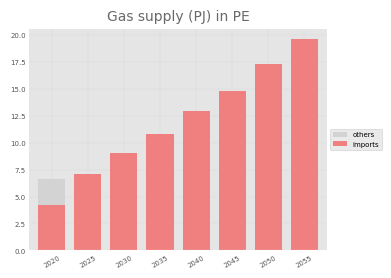

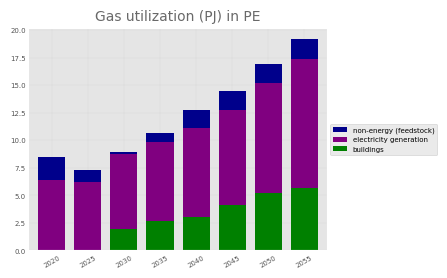

> WARNING: There is no solution data in the selected years and limits to be plotted for Coal supply (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Coal utilization (PJ)!


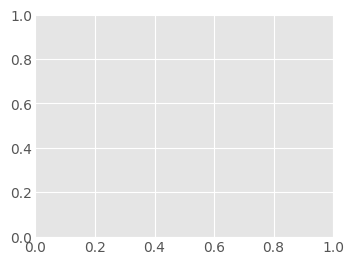

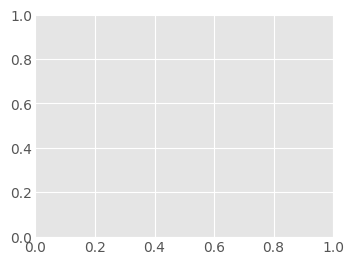

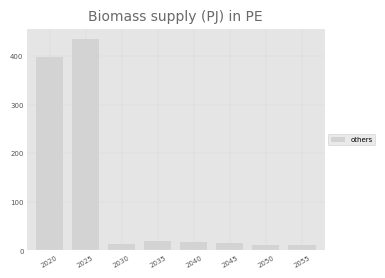

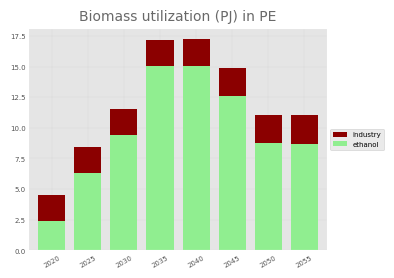

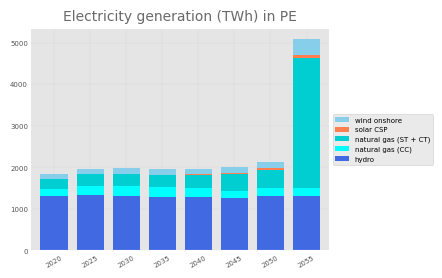

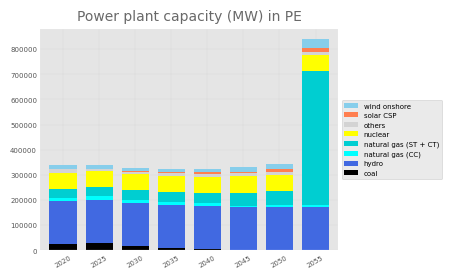

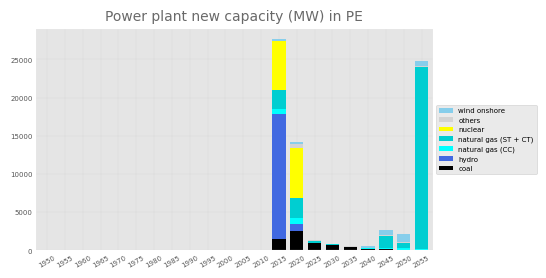

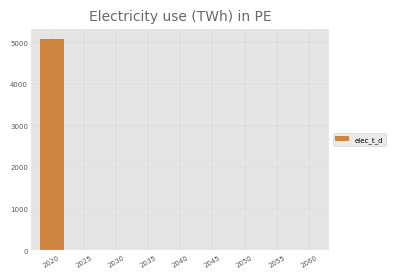

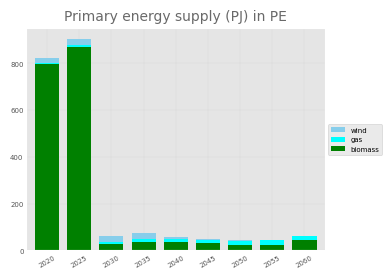

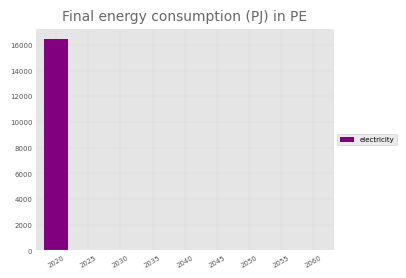

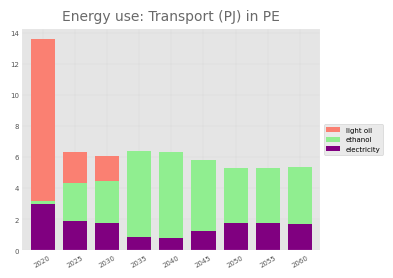

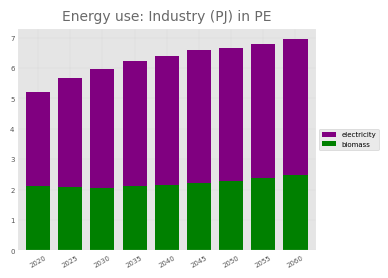

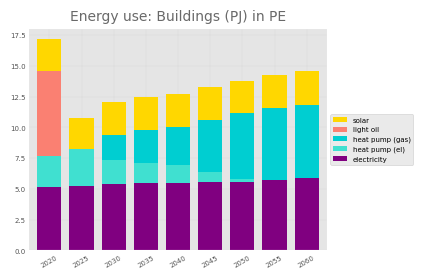

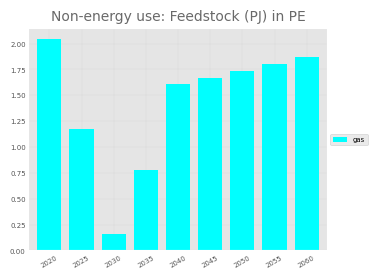

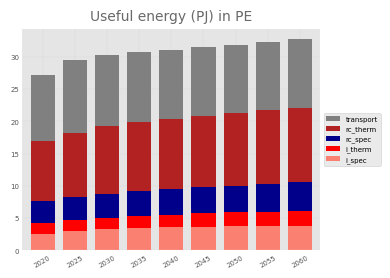

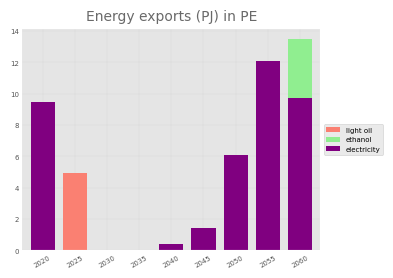

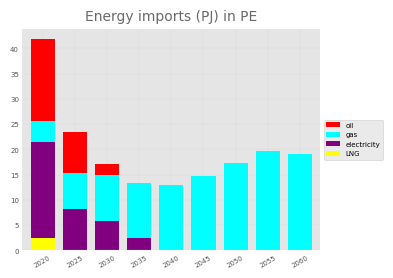

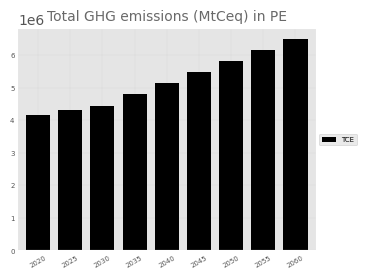

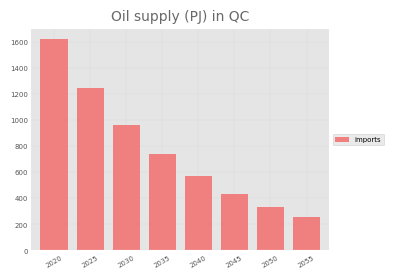

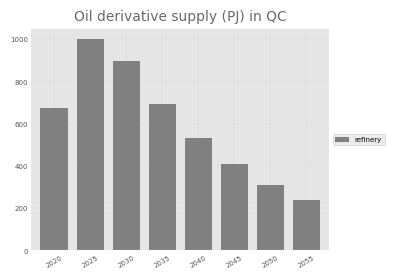

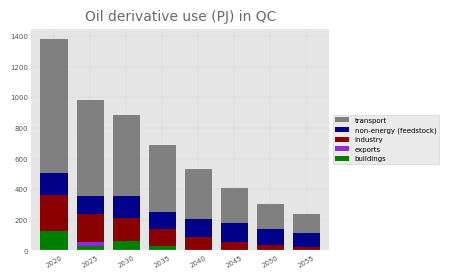

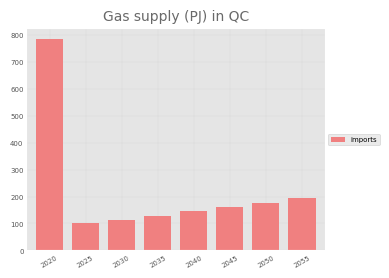

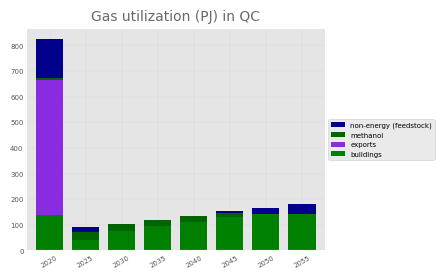

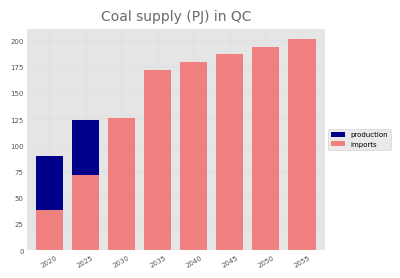

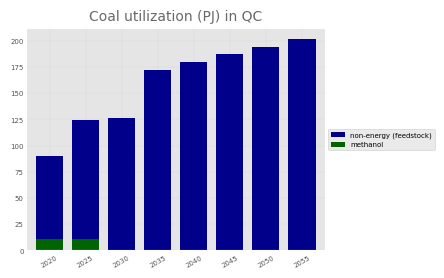

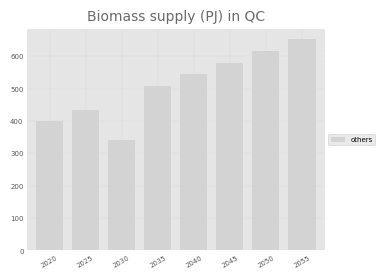

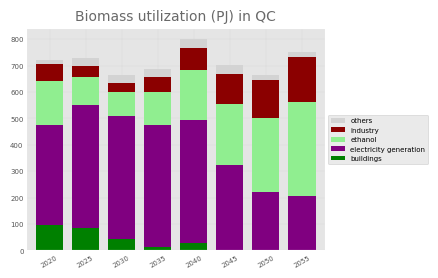

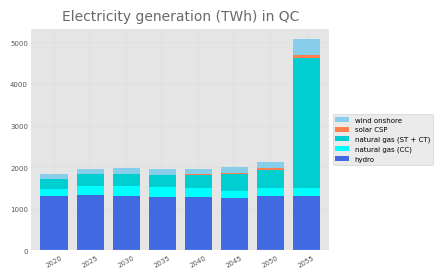

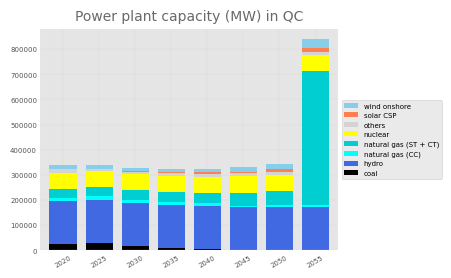

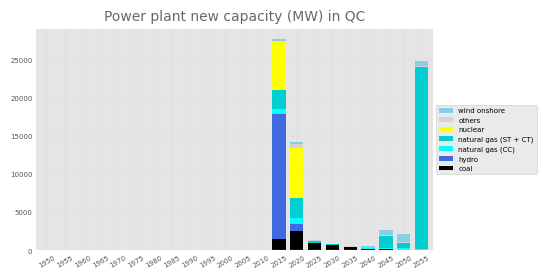

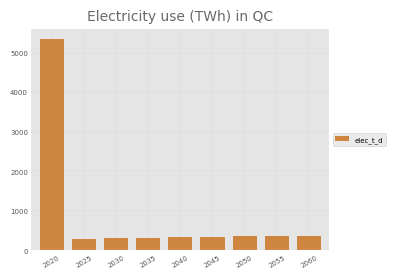

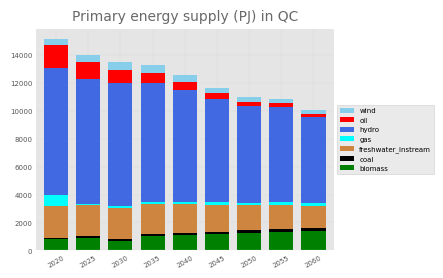

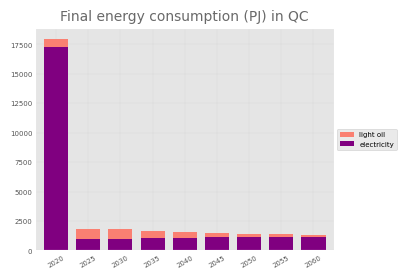

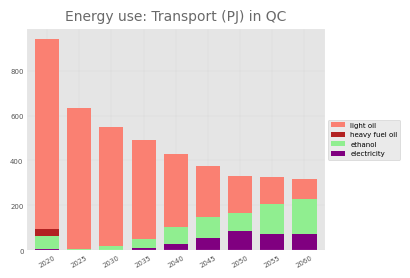

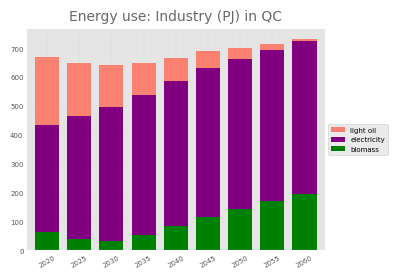

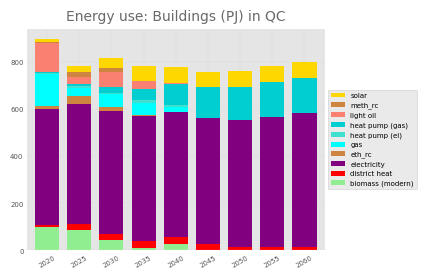

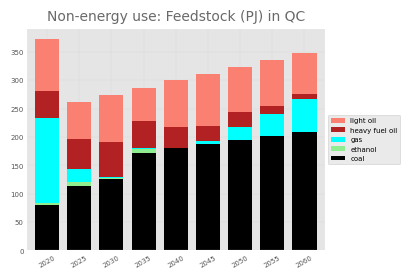

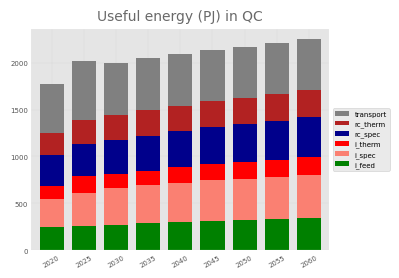

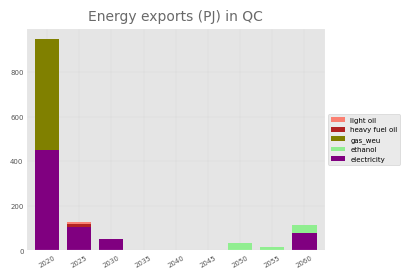

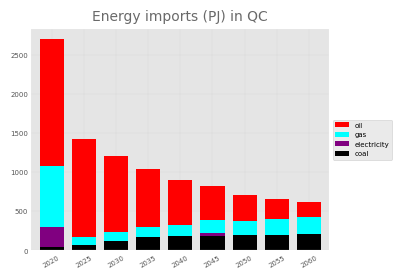

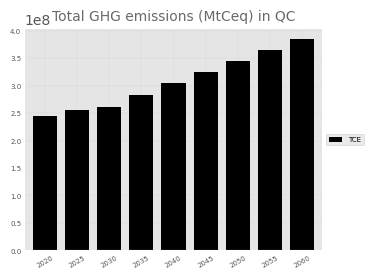

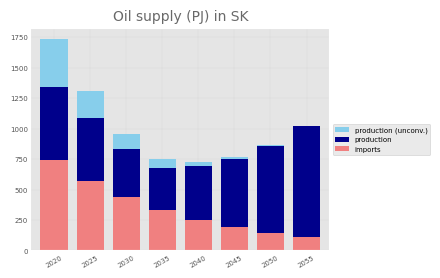

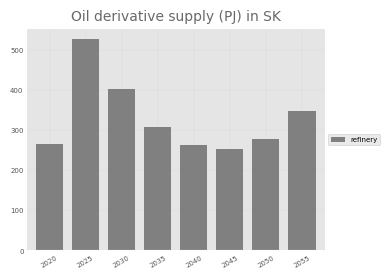

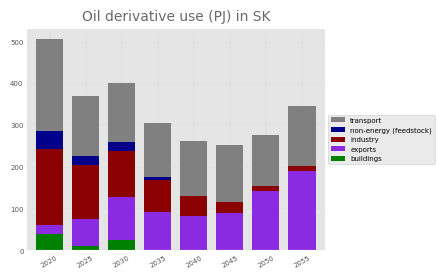

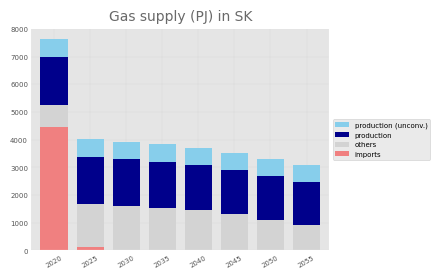

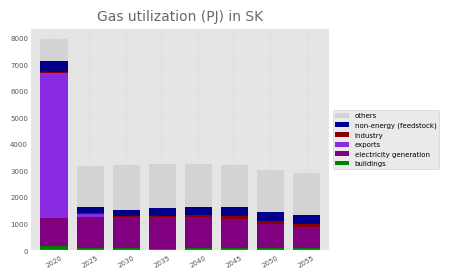

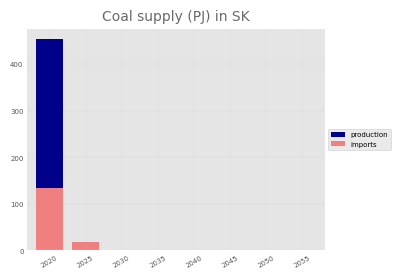

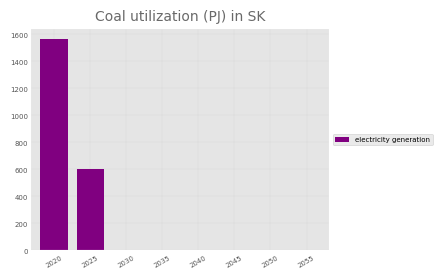

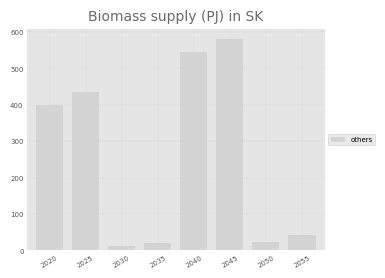

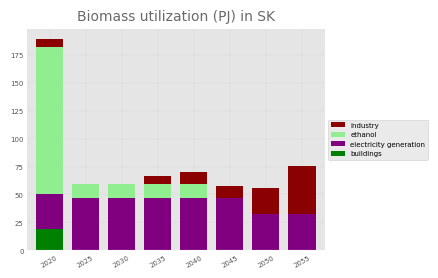

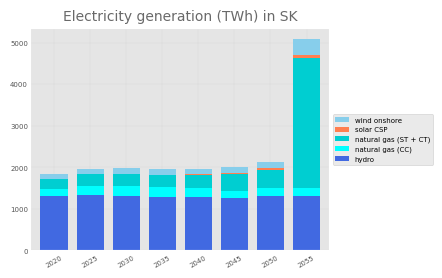

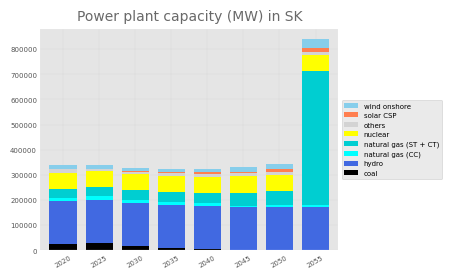

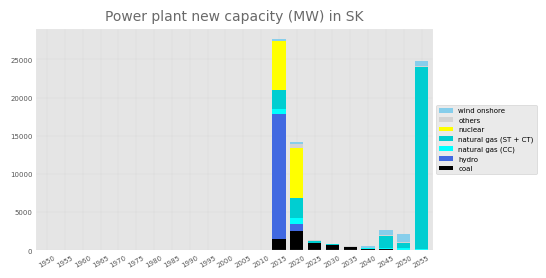

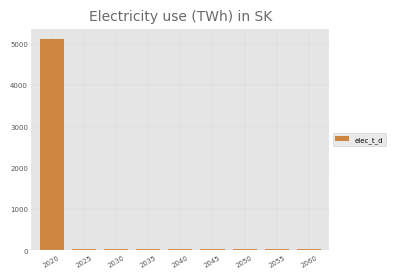

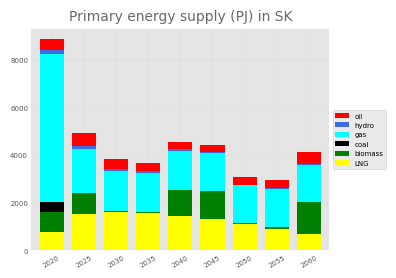

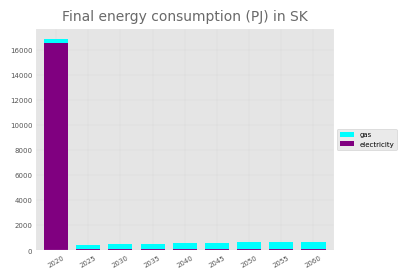

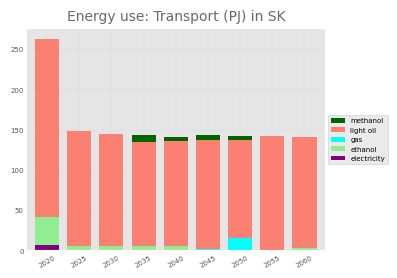

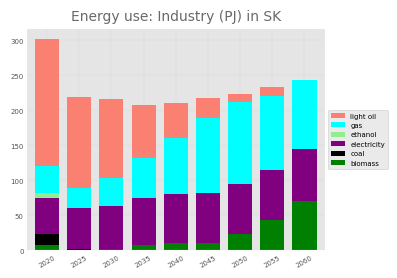

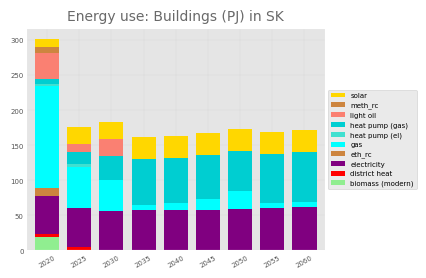

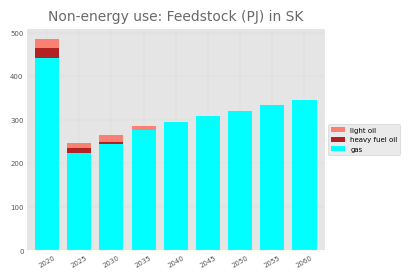

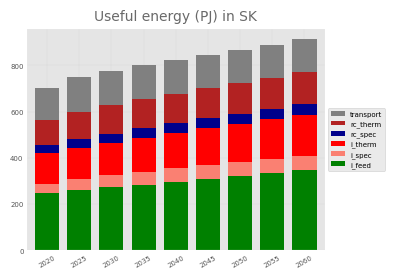

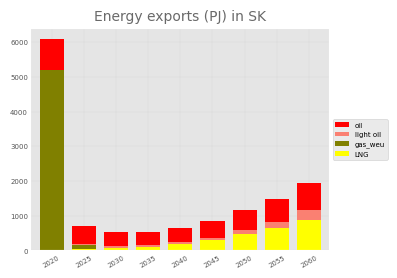

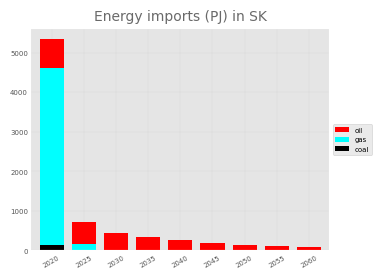

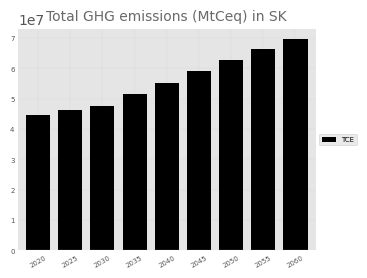

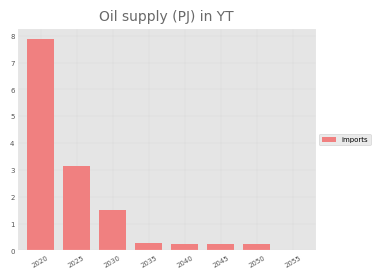

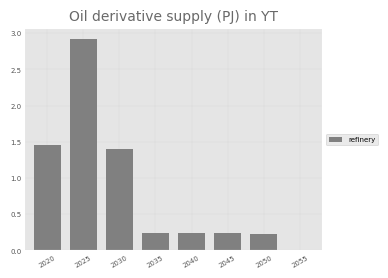

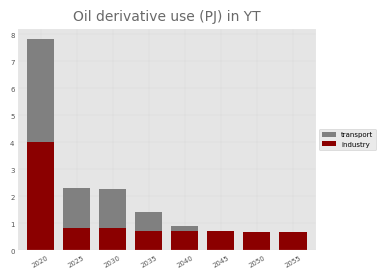

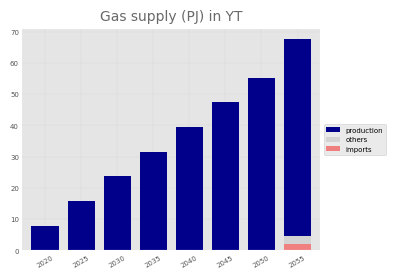

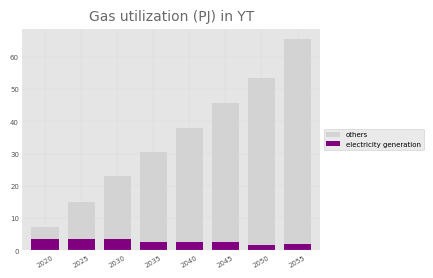

> WARNING: There is no solution data in the selected years and limits to be plotted for Coal supply (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Coal utilization (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Biomass supply (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Biomass utilization (PJ)!


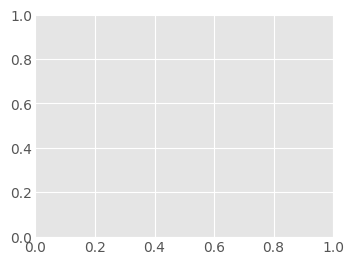

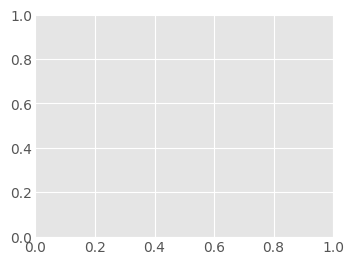

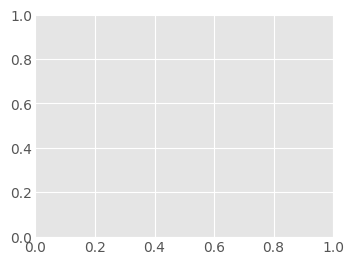

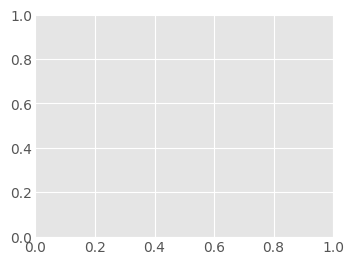

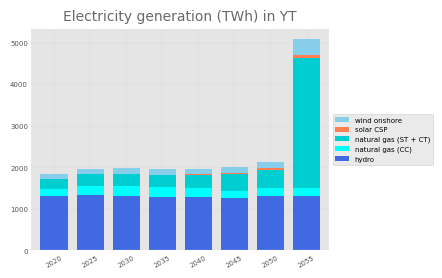

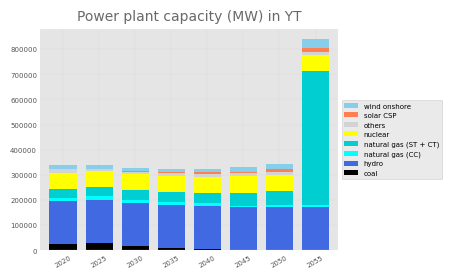

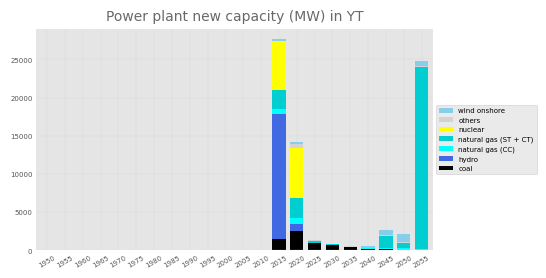

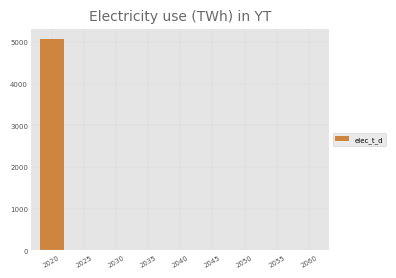

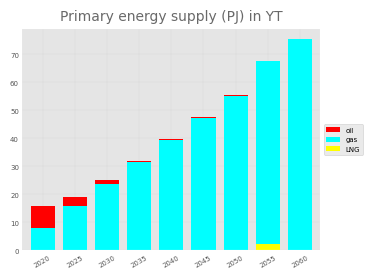

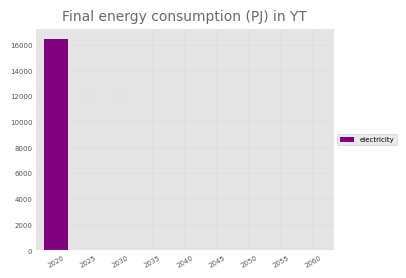

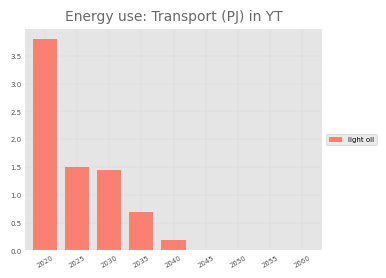

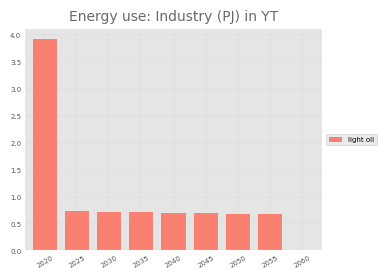

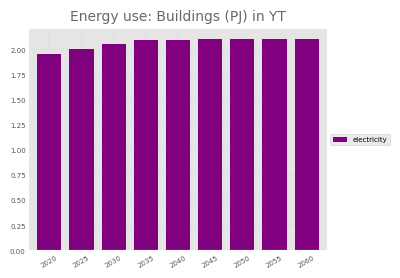

> WARNING: There is no solution data in the selected years and limits to be plotted for Non-energy use: Feedstock (PJ)!
> WARNING: There is no solution data in the selected years and limits to be plotted for Useful energy (PJ)!


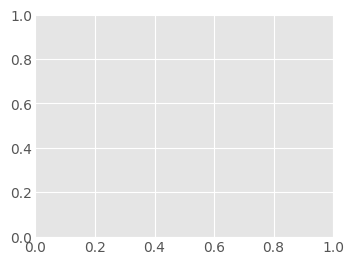

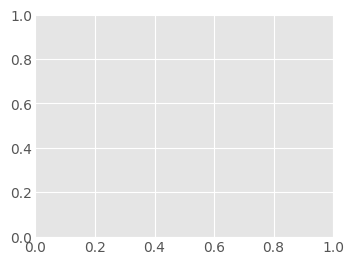

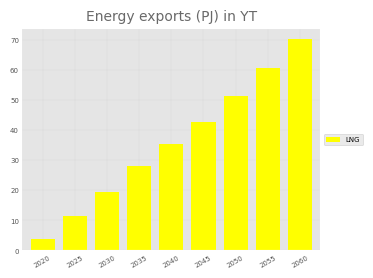

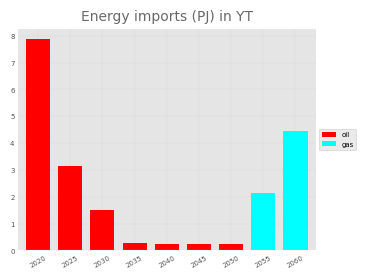

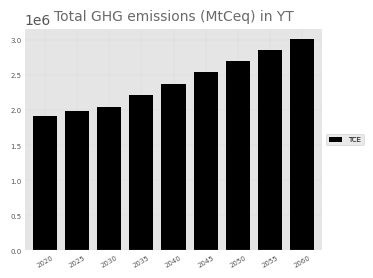

{'Electricity generation (TWh)':             hydro  natural gas (CC)  natural gas (ST + CT)  solar CSP  \
 2020  1310.802022        159.586932             250.864231   1.535997   
 2025  1325.358075        232.408445             271.851092   4.181109   
 2030  1319.566049        237.228010             281.866787   8.622334   
 2035  1297.080446        218.317940             295.657072  15.288531   
 2040  1275.987744        226.908996             303.894404  24.085576   
 2045  1267.569957        169.180548             394.581902  36.010774   
 2050  1311.017944        189.325377             429.097102  50.977244   
 2055  1305.309007        198.156416            3124.694908  70.514403   
 
       wind onshore  
 2020    119.677136  
 2025    132.074720  
 2030    134.760536  
 2035    133.760258  
 2040    140.939077  
 2045    137.402722  
 2050    151.931788  
 2055    386.600080  ,
 'Power plant capacity (MW)':               coal          hydro  natural gas (CC)  natural gas (ST + 

In [35]:
msg_plt.plotter(case=caseName,nodeloc=nodes,path=msg_folder/'output',yr_min=2020, yr_max=2060)

In [38]:
path=msg_folder/'output'

In [52]:
import os
import pandas as pd

def basic_report_to_pyam(files_path, output_file):
    """
    Function to process all .xlsx files in a directory, extract region and scenario data,
    process the data for each sheet, and save the final dataframe as a CSV.

    Args:
        directory_path (str): Path to the directory containing .xlsx files.
        output_file (str): Path to save the resulting CSV file.

    Returns:
        final_df (pd.DataFrame): The concatenated dataframe from all processed .xlsx files.
    """
    
    # Automatically list all .xlsx files in the directory
    file_paths = [os.path.join(files_path, file) for file in os.listdir(files_path) if file.endswith('.xlsx')]
    dfs = []

    # Process each file
    for file_path in file_paths:
    # Extract region and scenario from the file name
        file_name = os.path.basename(file_path)
        
        # Split file name using '__' to handle sections like baseline, version, and region
        parts = file_name.split('__')
        
        # Extract scenario, including the version, but without '__' (e.g., 'baseline v4')
        scenario = f"{parts[1]} {parts[2].split('_')[0]}"  # Extract 'baseline' and 'v4', separated by a space
        
        # Extract region from the part after 'v4_'
        region = parts[2].split('_')[1].split('.')[0]  # Extract region (e.g., 'PrinceEdwardIsland')
            
        # Open the Excel file and get sheet names
        xls = pd.ExcelFile(file_path)
        sheet_names = xls.sheet_names

        for sheet in sheet_names:
            df = pd.read_excel(file_path, sheet_name=sheet)

            # Process variable and unit from the sheet name
            variable, unit = sheet.split(' (')
            variable = variable.strip()  # Strip spaces from variable
            unit = unit.strip().rstrip(')')  # Strip spaces from unit and remove closing parenthesis

            # Rename the first column to 'time'
            df.rename(columns={df.columns[0]: 'time'}, inplace=True)

            # Melt the dataframe to have 'time' as id_vars, variable names in 'variable', and values in 'value'
            df = pd.melt(df, id_vars=['time'], var_name='variable', value_name='value')

            # Add the unit and processed variable names
            df['unit'] = unit
            df['variable'] = variable + '|' + df['variable']

            # Add region and scenario columns
            df['region'] = region
            df['scenario'] = scenario
            df['model'] = 'MESSAGEix-Canada'

            # Append the dataframe to the list
            dfs.append(df)

    # Concatenate all dataframes into a single dataframe
    final_df = pd.concat(dfs, ignore_index=True)

    # Filter the dataframe to only include data from 2020 onwards
    final_df = final_df[final_df['time'] >= 2020]

    # Save the final dataframe to a CSV file
    final_df.to_csv(output_file, index=False)

    return final_df



In [54]:
# Example usage:
basic_report_to_pyam(path, f'{caseName}.csv')


,time,variable,value,unit,region,scenario,model
14,2020,Oil supply|buildings,0.000000e+00,PJ,NorthwestTerritories,baseline v4,MESSAGEix-Canada
15,2025,Oil supply|buildings,0.000000e+00,PJ,NorthwestTerritories,baseline v4,MESSAGEix-Canada
16,2030,Oil supply|buildings,0.000000e+00,PJ,NorthwestTerritories,baseline v4,MESSAGEix-Canada
17,2035,Oil supply|buildings,0.000000e+00,PJ,NorthwestTerritories,baseline v4,MESSAGEix-Canada
18,2040,Oil supply|buildings,0.000000e+00,PJ,NorthwestTerritories,baseline v4,MESSAGEix-Canada
...,...,...,...,...,...,...,...
65609,2040,Total GHG emissions|TCE,5.138748e+06,MtCeq,PrinceEdwardIsland,baseline v4,MESSAGEix-Canada
65610,2045,Total GHG emissions|TCE,5.491158e+06,MtCeq,PrinceEdwardIsland,baseline v4,MESSAGEix-Canada
65611,2050,Total GHG emissions|TCE,5.825588e+06,MtCeq,PrinceEdwardIsland,baseline v4,MESSAGEix-Canada
65612,2055,Total GHG emissions|TCE,6.166189e+06,MtCeq,PrinceEdwardIsland,baseline v4,MESSAGEix-Canada
